# UniRemington - Cali<br>Facultad de Ingeniería - Línea de Énfasis III: Ciencia de Datos y Machine Learning<br>(ↄ) Diego Fernando Marin, 2026-2

## Datos del Estudiante

**Código**: 1005945264<br>
**Nombre**: Luz Carolina Hernandez Vega<br>
**Correo**: luz.hernandez.5264@miremington.edu.co

# Taller #2 - Titanic

## 0. Introducción

### ¿Qué vas a hacer en este taller?

Vas a realizar un **análisis exploratorio de datos (EDA) completo** sobre el dataset del Titanic: explorarás los datos, los limpiarás, los transformarás, los visualizarás y, sobre todo, los **interrogarás** para entender qué características de los pasajeros aumentaron o disminuyeron sus probabilidades de sobrevivir. Este taller es la continuación del Taller #1 (Encuesta de TV): allí practicaste con **Pandas** y **Matplotlib**; aquí sumas **Seaborn** (gráficos estadísticos), **NumPy** y una primera prueba de hipótesis con **SciPy**.


### Alcance

Al terminar serás capaz de:

1. Inspeccionar un dataset nuevo y **diagnosticar datos faltantes** con tablas y mapas de calor.
2. Construir **variables nuevas** (*feature engineering*): `Person`, `Alone`, `TCabin`, `TTitulo`.
3. Elegir y construir el gráfico adecuado con Seaborn (conteo, KDE, puntos, regresión, cajas, histogramas).
4. Aplicar y **justificar** estrategias de imputación (moda, promedio por grupo) y reconocer el sesgo que introducen.
5. Codificar variables categóricas como numéricas y leer una **matriz de correlación** con sentido crítico.
6. Distinguir entre **descripción**, **asociación** y **causalidad**, y comunicar con honestidad las limitaciones de tu análisis.


Tu análisis es exitoso si puedes:

- ✅ Explicar cada decisión tomada durante la limpieza de datos.
- ✅ Justificar tus visualizaciones con argumentos claros.
- ✅ Identificar patrones no obvios en los datos.
- ✅ Reconocer las limitaciones de tu análisis.
- ✅ Comunicar tus hallazgos a una audiencia no técnica.
- ✅ Formular hipótesis comprobables a partir de tus observaciones.

## 1. Contexto del problema

Imagina que eres analista de datos en una **empresa de seguros** que investiga patrones históricos de supervivencia en desastres marítimos. La gerencia quiere saber, a partir del caso del Titanic (1912), **qué características de una persona aumentaron o disminuyeron su probabilidad de sobrevivir**, para alimentar modelos de riesgo y protocolos de evacuación.

> **Pregunta central:** ¿Qué factores tuvieron más influencia sobre la supervivencia de los pasajeros del Titanic?

**¿Por qué EDA y no directamente un modelo?** Porque antes de predecir hay que *entender*. Un análisis exploratorio revela errores y vacíos en los datos, genera hipótesis y evita construir modelos sobre supuestos falsos. Además, en este dataset **faltan muchos datos** (edad, cabina) y la forma en que los rellenes **cambia las conclusiones**: ese es el corazón del taller.



### Diccionario de datos

| Variable | Descripción | Tipo esperado |
|---|---|---|
| `PassengerId` | Identificador del pasajero | entero |
| `Survived` | 0 = no sobrevivió, 1 = sobrevivió | entero (categórica binaria) |
| `Pclass` | Clase del tiquete: 1 = alta, 2 = media, 3 = baja | entero (categórica ordinal) |
| `Name` | Nombre completo (incluye el título: Mr, Mrs, Miss…) | texto |
| `Sex` | `male` / `female` | categórica |
| `Age` | Edad en años | decimal (con faltantes) |
| `SibSp` | N.º de hermanos/cónyuge a bordo | entero |
| `Parch` | N.º de padres/hijos a bordo | entero |
| `Ticket` | Número de tiquete | texto |
| `Fare` | Tarifa pagada | decimal |
| `Cabin` | Cabina (la letra indica la cubierta) | texto (muchos faltantes) |
| `Embarked` | Puerto de embarque: C = Cherbourg, Q = Queenstown, S = Southampton | categórica |


## 2. Preparación del entorno

Esta celda ya está completa: es el **ejemplo resuelto** que te muestra el estilo de las siguientes. Ejecútala y lee cada línea.


In [ ]:
# 1) Importamos las librerías con sus alias convencionales
import pandas as pd                 # tablas (DataFrame)
import numpy as np                  # cálculo numérico y condiciones vectorizadas
import matplotlib.pyplot as plt     # gráficos base (Seaborn se apoya en él)
import seaborn as sns               # gráficos estadísticos de alto nivel
from scipy import stats             # pruebas estadísticas (la usaremos en la Parte 6)

In [ ]:
# 2) Estilo global: todos los gráficos heredan esta configuración
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (8, 5)   # tamaño por defecto (ancho, alto) en pulgadas
plt.rcParams['axes.titlesize'] = 13

**Nota**: el *dataset* contiene datos de quiénes sobrevivieron, quiénes no sobrevivieron, y quiénes no se sabe. Solo vamos a tener en cuenta los 2 primeros grupos, el 3er grupo lo usamos en el Taller #3.

In [ ]:
# 3) Cargamos los datos directamente desde la URL
df = pd.read_csv('https://paste.c-net.org/MarvelJinxed', nrows=891)

> **Teoría — ¿por qué varias librerías?** Cada una resuelve un problema distinto: Pandas organiza y transforma tablas; NumPy ofrece operaciones numéricas rápidas; Matplotlib dibuja; Seaborn dibuja gráficos *estadísticos* con muy pocas líneas (agrupa, calcula intervalos de confianza, aplica temas); SciPy contiene pruebas estadísticas. Se combinan porque se construyeron para ser compatibles entre sí.

> **Tip — si algo sale mal al cargar.** Si obtienes **una sola columna** con todo pegado, el separador no es la coma (en el Taller #1 era `|`). Prueba `pd.read_csv(url, sep='|')` o deja que Pandas lo adivine con `pd.read_csv(url, sep=None, engine='python')`. Si la descarga directa falla, descarga el archivo y cárgalo desde disco.

> **Tip — copia de seguridad.** Muchas transformaciones de este taller **modifican `df`**. Si te equivocas y quieres volver al inicio, vuelve a ejecutar la celda de carga.


## Parte 1 — Primer contacto con los datos (Pasos 1–5)

> **Teoría.** Antes de graficar nada, un analista responde cuatro preguntas: *¿cuánto hay?* (dimensiones), *¿de qué tipo es cada columna?* (tipos), *¿cómo se ve?* (muestra) y *¿qué falta?* (nulos). Los datos faltantes no son un detalle: **pueden sesgar todas tus conclusiones**.


### Paso 1. ¿Cuántos pasajeros (filas) y variables (columnas) hay?

**Lógica:** `shape` devuelve una tupla `(filas, columnas)`.


In [ ]:
# Obtén las dimensiones del DataFrame.
# Pista: shape es un ATRIBUTO (no lleva paréntesis).

df.shape

(891, 12)

### Paso 2. ¿Cuáles son las variables, sus nombres y tipos?

**Lógica:** `info()` muestra nombre, **cantidad de valores no nulos** y tipo (`dtype`) de cada columna. Compara el número de no nulos con el total de filas: ahí se descubren los datos faltantes.



In [ ]:
# Muestra el resumen estructural del DataFrame.
# Pista: info() es un MÉTODO (lleva paréntesis) e imprime directamente.

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


> En Pandas 3.x las columnas de texto se muestran como `str`; en versiones anteriores, como `object`. Son equivalentes para este taller.


### Paso 3. Muestra las primeras 10 filas


In [ ]:
# Muestra las 10 primeras filas.
# Pista: head(n) recibe el número de filas.

df.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


### Paso 4. Estadísticas descriptivas

**Lógica:** `describe()` resume las columnas **numéricas** (conteo, media, desviación, mínimo, cuartiles, máximo). Para las de texto hay que pedirlo aparte.


In [ ]:
# 1. Estadísticas descriptivas de las columnas numéricas.

df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [ ]:
# 2. Estadísticas de las columnas NO numéricas.
#    Pista: df.select_dtypes(exclude='number').describe()
#    (mira 'unique' y 'top': ¿cuántos nombres, tiquetes y cabinas distintos hay?)

df.select_dtypes(exclude='number').describe()

,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,G6,S
freq,1,577,7,4,644


### Paso 5. Identificar datos faltantes (con tabla y con mapa de calor)

**Lógica:** `df.isnull()` devuelve una tabla de `True/False` (True = falta el dato). Sumarla da el conteo por columna. Un **heatmap** de esa tabla muestra *dónde* faltan y si hay patrones (por ejemplo, filas a las que les faltan varias cosas a la vez).



In [ ]:
# 1. Cuenta los nulos por columna con isnull().sum().

df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


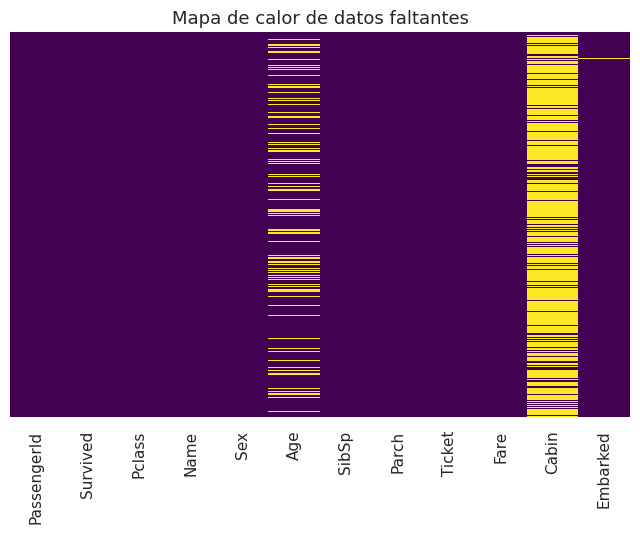

In [ ]:
# 2. Dibuja el mapa de calor de df.isnull():
#    sns.heatmap(..., cbar=False, yticklabels=False, cmap='viridis')

sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap='viridis')
plt.title('Mapa de calor de datos faltantes')
plt.show()

In [ ]:
# 3. Añade un título con plt.title(...) y cierra con plt.show().

# (El título y plt.show() quedaron en la celda anterior: Colab muestra cada figura al terminar la celda,
# y si el título va en otra celda se aplicaría a una figura vacía.)

### Evaluación — Parte 1

- **E1.1 (conceptual).** ¿Cuántos pasajeros hay en total? ¿Qué columnas son numéricas y cuáles categóricas? Atención: `Survived` y `Pclass` aparecen como números, pero ¿se comportan como números (¿tiene sentido promediar `Pclass`?)


**Respuesta:** Hay 891 pasajeros en total (el DataFrame tiene 891 filas y 12 columnas). Las columnas numéricas son PassengerId, Age, SibSp, Parch y Fare. Las categóricas son Name, Sex, Ticket, Cabin y Embarked, y también Survived y Pclass, aunque aparezcan como números enteros. Pclass no se comporta como un número: no tiene sentido promediarla, porque un promedio de 2.3 no corresponde a ninguna clase real y solo indica un orden (1ª, 2ª, 3ª). Survived es 0/1, así que su promedio solo sirve como proporción de sobrevivientes.

- **E1.2 (conceptual).** ¿Qué problemas "obvios" observas en los datos (columnas inútiles para el análisis, tipos extraños, faltantes)?


**Respuesta:** PassengerId, Name y Ticket casi no sirven para el análisis (891 nombres distintos y 681 tiquetes distintos, prácticamente identificadores). Survived y Pclass vienen como enteros aunque son categorías. Hay muchos faltantes: Cabin tiene 204 datos de 891, Age tiene 714 y Embarked tiene 889. Además, Cabin tiene 147 valores distintos, lo que la hace difícil de usar tal cual, y Fare tiene un mínimo de 0 y un máximo de 512.33 frente a una mediana de 14.45, así que hay valores extremos.

- **E1.3 (código).** Calcula el **porcentaje** de datos faltantes por columna, ordenado de mayor a menor.


In [ ]:
# Reto E1.3 — Pista: isnull().mean() devuelve la proporción de nulos por columna;
# multiplica por 100, redondea con round(1) y ordena con sort_values(ascending=False).

(df.isnull().mean() * 100).round(1).sort_values(ascending=False)

,0
Cabin,77.1
Age,19.9
Embarked,0.2
PassengerId,0.0
Name,0.0
Pclass,0.0
Survived,0.0
Sex,0.0
Parch,0.0
SibSp,0.0


- **E1.4 (conceptual).** ¿Qué columnas tienen más datos faltantes? ¿Podrían sesgar el análisis? Piensa: ¿los faltantes parecen "al azar" o tienen una causa?


**Respuesta:** Las columnas con más faltantes son Cabin (77.1 %), Age (19.9 %) y Embarked (0.2 %). Sí podrían sesgar el análisis, porque no parece que falten al azar. En Cabin, lo más probable es que solo se registrara la cabina de ciertos pasajeros (posiblemente los de clases más altas), y en Age la falta de edad puede estar ligada a quiénes eran más difíciles de registrar. Eso habría que comprobarlo más adelante. Embarked tiene solo 2 faltantes, así que casi no afecta.

- **E1.5 (conceptual — reflexión).** ¿Por qué usamos varias bibliotecas en lugar de una sola? Da un ejemplo de tarea para cada una.


**Respuesta:** Porque cada biblioteca está hecha para una tarea distinta y se complementan. Ejemplos: Pandas para cargar y organizar la tabla (read_csv, groupby); NumPy para cálculos y condiciones vectorizadas (np.where para crear Person); Matplotlib para dibujar gráficos base (plt.title, plt.show); Seaborn para gráficos estadísticos con pocas líneas (sns.countplot, sns.heatmap); y SciPy para pruebas estadísticas (chi-cuadrado). Se pueden combinar porque son compatibles entre sí.

## Parte 2 — Conociendo a los pasajeros (Pasos 6–10)

> **Teoría — dos herramientas nuevas.**
> - `sns.countplot(data=df, x='col', hue='otra')` cuenta filas por categoría; `hue` divide cada barra por una segunda variable.
> - `pd.crosstab(a, b)` produce la **tabla cruzada** (conteos de cada combinación). Con `normalize='columns'` (o `'index'`) los conteos pasan a **proporciones** que suman 1 por columna (o por fila).
>
> Para **comparar grupos de distinto tamaño** usa proporciones, no conteos absolutos.


### Paso 6. Distribución por género y su cruce con la clase


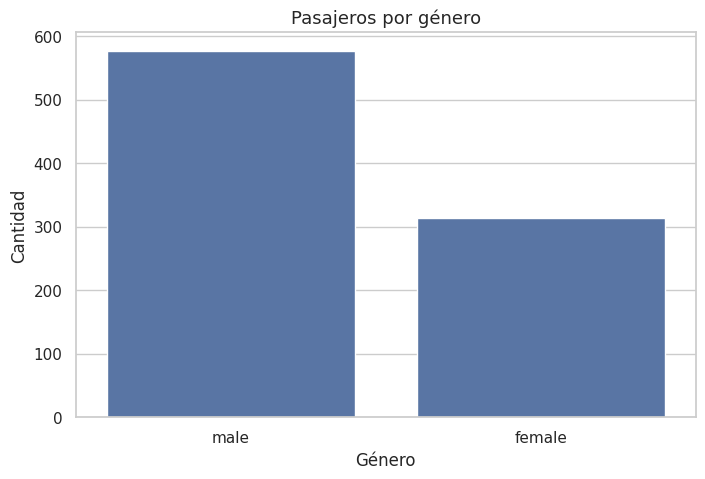

In [ ]:
# 1. Gráfico de conteo de 'Sex'.

sns.countplot(data=df, x='Sex')
plt.title('Pasajeros por género')
plt.xlabel('Género')
plt.ylabel('Cantidad')
plt.show()

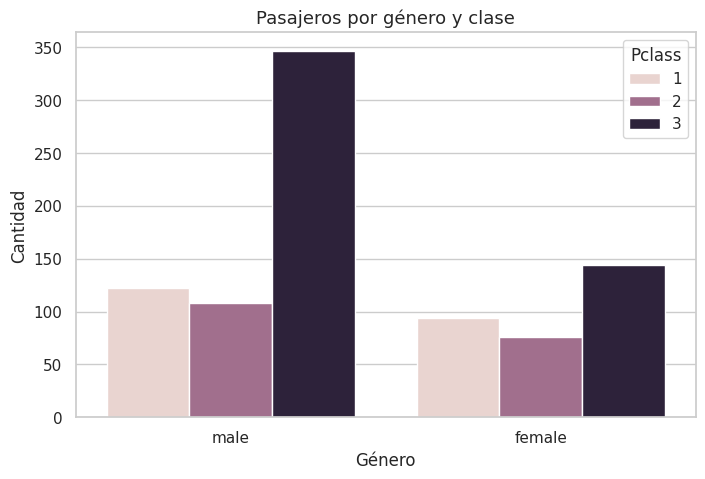

In [ ]:
# 2. Gráfico de conteo de 'Sex' con hue='Pclass'.

sns.countplot(data=df, x='Sex', hue='Pclass')
plt.title('Pasajeros por género y clase')
plt.xlabel('Género')
plt.ylabel('Cantidad')
plt.show()

In [ ]:
# 3. Tabla cruzada Sex x Pclass NORMALIZADA POR COLUMNAS:
#    ¿qué proporción de cada clase son mujeres?

pd.crosstab(df['Sex'], df['Pclass'], normalize='columns')

Pclass,1,2,3
Sex,,,
female,0.435185,0.413043,0.293279
male,0.564815,0.586957,0.706721


### Paso 7. Distribución de edades

**Lógica:** un **histograma** divide la variable numérica en intervalos (*bins*) y cuenta cuántos casos caen en cada uno. `Age` tiene nulos: Seaborn los ignora al graficar, pero es bueno hacerlo explícito con `dropna()`.


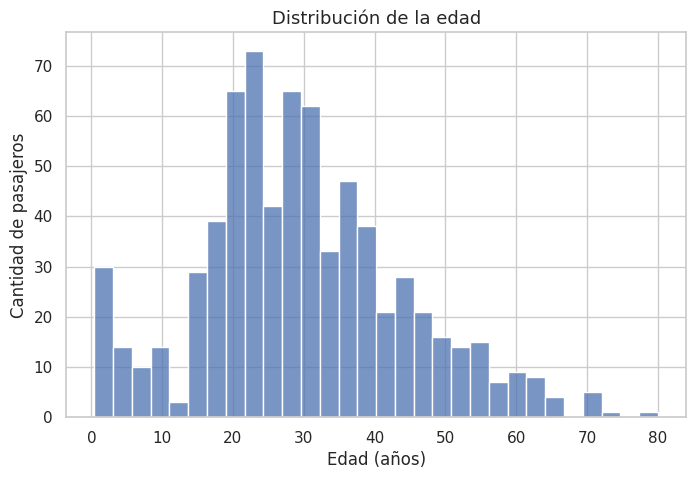

In [ ]:
# 1. Histograma de la edad: sns.histplot(df['Age'].dropna(), bins=30)
#    Añade título y etiquetas de los ejes.

sns.histplot(df['Age'].dropna(), bins=30)
plt.title('Distribución de la edad')
plt.xlabel('Edad (años)')
plt.ylabel('Cantidad de pasajeros')
plt.show()

In [ ]:
# 2. Calcula la edad promedio (Pandas ignora los NaN automáticamente).

df['Age'].mean()

np.float64(29.69911764705882)

In [ ]:
# 3. Explora: mediana, mínimo y máximo de la edad.

print('Mediana:', df['Age'].median())
print('Mínimo:', df['Age'].min())
print('Máximo:', df['Age'].max())

Mediana: 28.0
Mínimo: 0.42
Máximo: 80.0


### Paso 8. Crear la variable `Person` (hombre, mujer o niño)

**Lógica:** `np.where(condición, valor_si_True, valor_si_False)` crea una columna de forma **vectorizada** (sin `for`). Aquí: si `Age < 16` → `'child'`; si no, se conserva el valor de `Sex`.


In [ ]:
# Crea df['Person'] con np.where:
#   condición: df['Age'] < 16
#   si True: 'child'      si False: df['Sex']

df['Person'] = np.where(df['Age'] < 16, 'child', df['Sex'])

In [ ]:
# Luego cuenta cuántos hay de cada tipo con value_counts().

df['Person'].value_counts()

,count
Person,
male,537
female,271
child,83


> **Advertencia — los NaN y las comparaciones.** En Pandas/NumPy, `NaN < 16` da `False`. Por lo tanto, **un pasajero sin edad nunca será `child`**: se queda con su sexo. Es un sesgo silencioso. Lo investigarás en E2.5.


### Paso 9. ¿Cuántos niños viajaban en cada clase?


In [ ]:
# Tabla cruzada de 'Pclass' (filas) contra 'Person' (columnas).

pd.crosstab(df['Pclass'], df['Person'])

Person,child,female,male
Pclass,,,
1,6,91,119
2,19,66,99
3,58,114,319


### Paso 10. Gráficos de densidad (KDE) de la edad

> **Teoría — KDE.** La *estimación de densidad por kernel* es un "histograma suavizado": la curva muestra dónde se concentran los valores. Con `hue` se superponen varias curvas. Usa `common_norm=False` para que **cada grupo se normalice por separado** (si no, los grupos grandes "aplastan" a los pequeños).



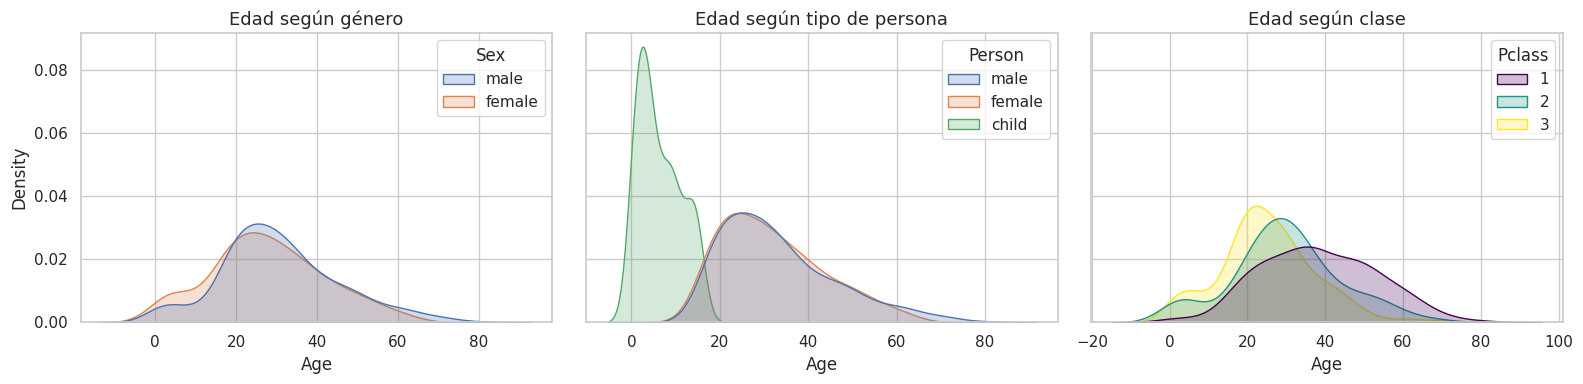

In [ ]:
# Crea una figura de 1 fila x 3 columnas: fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)

# Dibuja en cada eje (parámetro ax=axes[i]) un sns.kdeplot(data=df, x='Age', hue=..., fill=True, common_norm=False):
#   axes[0] -> hue='Sex'
#   axes[1] -> hue='Person'
#   axes[2] -> hue='Pclass'   (añade palette='viridis')

# Ponle un título a cada eje con axes[i].set_title(...) y cierra con plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)

sns.kdeplot(data=df, x='Age', hue='Sex', fill=True, common_norm=False, ax=axes[0])
axes[0].set_title('Edad según género')

sns.kdeplot(data=df, x='Age', hue='Person', fill=True, common_norm=False, ax=axes[1])
axes[1].set_title('Edad según tipo de persona')

sns.kdeplot(data=df, x='Age', hue='Pclass', fill=True, common_norm=False, palette='viridis', ax=axes[2])
axes[2].set_title('Edad según clase')

plt.tight_layout()
plt.show()

### Evaluación — Parte 2


- **E2.1 (conceptual).** ¿Hay diferencias en la composición de género entre clases? Apóyate en la tabla normalizada del Paso 6.


**Respuesta:** Sí hay diferencias. Según la tabla normalizada del Paso 6, las mujeres son el 43.5 % de la primera clase, el 41.3 % de la segunda y solo el 29.3 % de la tercera. Los hombres son el 56.5 %, 58.7 % y 70.7 % respectivamente. Es decir, en tercera clase predominan claramente los hombres, mientras que en primera y segunda la composición está más equilibrada.

- **E2.2 (código).** Calcula la proporción de menores de 16 años en cada clase (no el conteo).


In [ ]:
# Retos E2.2 -> (df['Age'] < 16).groupby(df['Pclass']).mean()

(df['Age'] < 16).groupby(df['Pclass']).mean()

,Age
Pclass,
1,0.027778
2,0.103261
3,0.118126


- **E2.3 (conceptual).** Describe la distribución de edades del Titanic. ¿Cómo era el pasajero "típico"?


**Respuesta:** La edad promedio es de 29.7 años y la mediana de 28, con un mínimo de 0.42 y un máximo de 80. La mayoría de los pasajeros está entre los 20 y los 40 años, y la distribución se alarga hacia la derecha (la media es un poco mayor que la mediana) porque hay algunos pasajeros mayores. También hay un grupo pequeño de niños muy pequeños. El pasajero típico era un adulto joven de unos 28 a 30 años, y según el Paso 9 lo más probable es que viajara en tercera clase (491 de los 891 pasajeros).

- **E2.4 (conceptual).** Según los KDE por clase, ¿qué clase tiene pasajeros de más edad? Propón una explicación social (no estadística) para esa diferencia.


**Respuesta:** Según los KDE por clase, la primera clase tiene los pasajeros de más edad: su curva está desplazada hacia la derecha, con más densidad entre los 30 y los 50 años, mientras que la tercera clase es la más joven (su pico está cerca de los 20 a 25 años). Una posible explicación social es que las personas mayores habían tenido más tiempo para acumular dinero y por eso podían pagar un tiquete caro, mientras que los jóvenes viajaban con menos recursos, por ejemplo emigrando para buscar trabajo.

- **E2.5 (código + conceptual).** ¿Cuántos pasajeros **sin edad** quedaron clasificados como `male` o `female` en `Person`? ¿Por qué eso puede subestimar el número de niños?


In [ ]:
# Retos E2.5-> filtra df[df['Age'].isnull()] y cuenta sus valores de 'Person'

df[df['Age'].isnull()]['Person'].value_counts()

,count
Person,
male,124
female,53


**Respuesta:** Los 177 pasajeros sin edad quedaron clasificados así: 124 como male y 53 como female (ninguno como child). Esto pasa porque NaN < 16 da False, entonces a esos pasajeros se les asigna su sexo aunque sean niños. Por eso el número de niños (83) puede estar subestimado, ya que algunos de los pasajeros sin edad podrían haber sido menores de 16 años.

## Parte 3 — Ubicación, embarque y composición familiar (Pasos 11–15)

> **Teoría — extraer información de texto.** Con una Serie de texto, el accesor `.str` aplica operaciones a cada elemento a la vez: `serie.str[0]` toma el primer carácter. En `Cabin` (por ejemplo `'C85'`) la primera letra indica la **cubierta**.



### Paso 11. Extraer la cubierta de la cabina


In [ ]:
# 1. Guarda en 'cabinas' las cabinas NO nulas: df['Cabin'].dropna()

cabinas = df['Cabin'].dropna()

In [ ]:
# 2. Crea 'cubierta' tomando la primera letra de cada cabina (.str[0]).

cubierta = cabinas.str[0]

In [ ]:
# 3. Muestra los conteos por cubierta con value_counts().
#    NO modifiques df todavía: lo haremos en la Parte 5.

cubierta.value_counts()

,count
Cabin,
C,59
B,47
D,33
E,32
A,15
F,13
G,4
T,1


### Paso 12. Gráfico de conteo por cubierta (con depuración de anómalos)


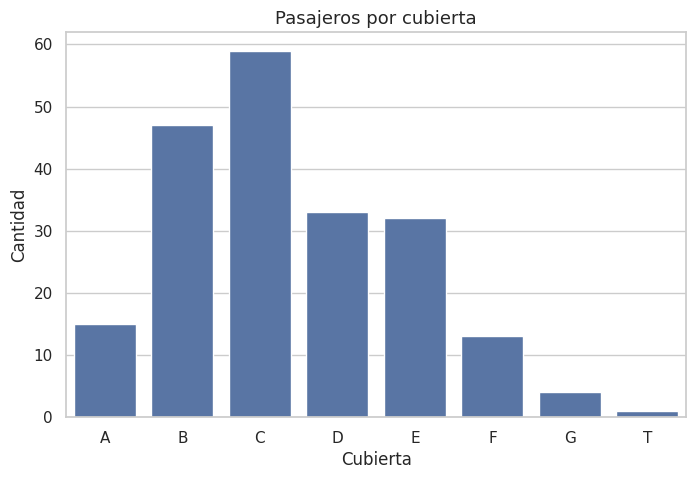

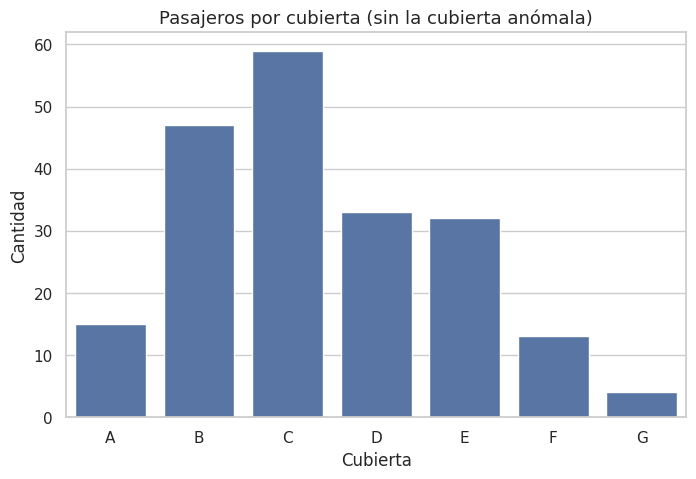

In [ ]:
# 1. Dibuja sns.countplot(x=cubierta, order=sorted(cubierta.unique())) con título y etiquetas.

# 2. Si encuentras una cubierta con un solo registro (anómala), elimínala de 'cubierta'
#    (cubierta = cubierta[cubierta != '?']) y vuelve a graficar.

sns.countplot(x=cubierta, order=sorted(cubierta.unique()))
plt.title('Pasajeros por cubierta')
plt.xlabel('Cubierta')
plt.ylabel('Cantidad')
plt.show()

# La cubierta con un solo registro es 'T' (la pista decía '?', pero en estos datos la anómala es 'T').
cubierta = cubierta[cubierta != 'T']

sns.countplot(x=cubierta, order=sorted(cubierta.unique()))
plt.title('Pasajeros por cubierta (sin la cubierta anómala)')
plt.xlabel('Cubierta')
plt.ylabel('Cantidad')
plt.show()

### Paso 13. Puerto de embarque y clase


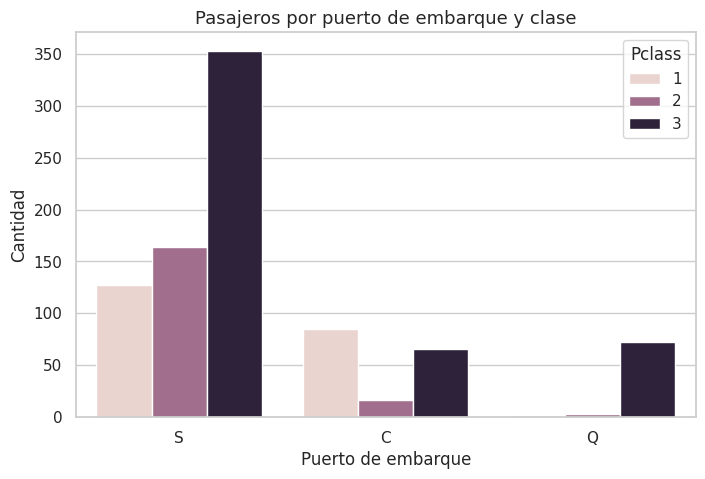

Pclass,1,2,3
Embarked,,,
C,0.505952,0.101190,0.392857
Q,0.025974,0.038961,0.935065
S,0.197205,0.254658,0.548137


In [ ]:
# 1. Gráfico de conteo de 'Embarked' con hue='Pclass'.

# 2. Tabla cruzada Embarked x Pclass normalizada por FILAS (normalize='index'):
#    ¿qué composición de clases tiene cada puerto?

sns.countplot(data=df, x='Embarked', hue='Pclass')
plt.title('Pasajeros por puerto de embarque y clase')
plt.xlabel('Puerto de embarque')
plt.ylabel('Cantidad')
plt.show()

pd.crosstab(df['Embarked'], df['Pclass'], normalize='index')

### Paso 14. Crear la variable `Alone` (solo vs. con familia)

**Lógica:** `SibSp + Parch` es el número de familiares a bordo. Si es 0, viaja solo.


In [ ]:
# 1. Crea df['Familia'] = df['SibSp'] + df['Parch']

df['Familia'] = df['SibSp'] + df['Parch']

In [ ]:
# 2. Crea df['Alone'] con np.where: 'with Family' si Familia > 0, 'Alone' si no.

df['Alone'] = np.where(df['Familia'] > 0, 'with Family', 'Alone')

In [ ]:
# 3. Calcula la proporción de cada categoría con value_counts(normalize=True).

df['Alone'].value_counts(normalize=True)

,proportion
Alone,
Alone,0.602694
with Family,0.397306


### Paso 15. Visualizar la distribución de `Alone`


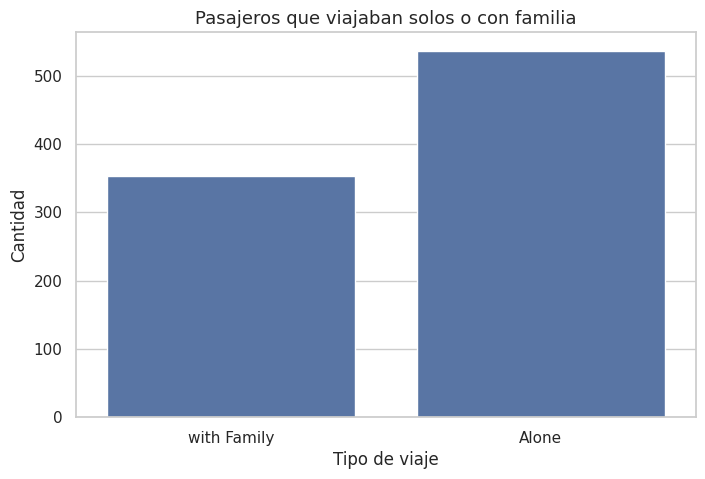

In [ ]:
# Gráfico de conteo de 'Alone' (con título y etiquetas).

sns.countplot(data=df, x='Alone')
plt.title('Pasajeros que viajaban solos o con familia')
plt.xlabel('Tipo de viaje')
plt.ylabel('Cantidad')
plt.show()

### Evaluación — Parte 3


- **E3.1 (código).** ¿Qué porcentaje de pasajeros tiene información de cabina?


In [ ]:
# Reto E3.1 — Pista: df['Cabin'].notna().mean() * 100

df['Cabin'].notna().mean() * 100

np.float64(22.895622895622896)

- **E3.2 (conceptual).** ¿Qué cubiertas eran las más ocupadas? ¿Qué implicaciones tiene que falten tantos datos de cabina? ¿Esa "ocupación" refleja de verdad el barco?


**Respuesta:** Entre los pasajeros con cabina registrada, las cubiertas más ocupadas fueron C (59), B (47), D (33) y E (32); las menos ocupadas fueron A (15), F (13) y G (4). Pero solo el 22.9 % de los pasajeros tiene información de cabina, así que esa "ocupación" no refleja de verdad el barco: de 687 pasajeros no sabemos dónde estaban alojados, y es posible que los datos solo se hayan registrado para cierto tipo de pasajeros (por ejemplo, los de clases altas). Cualquier conclusión sobre las cubiertas es parcial.

- **E3.3 (conceptual).** En el Paso 12, ¿era correcto eliminar la cubierta anómala? Da un argumento a favor y uno en contra.


**Respuesta:** A favor: la cubierta T tiene un solo registro, y con un solo pasajero no se puede sacar ninguna conclusión estadística; además, podría ser un error de captura que distorsiona el gráfico. En contra: puede ser un dato real y al eliminarlo se pierde información; no tenemos pruebas de que sea un error, y quitarlo es una decisión que cambia los datos sin una razón comprobada. En el Paso 12 solo se quitó de la serie cubierta y no del DataFrame df.

- **E3.4 (conceptual).** ¿Existe relación entre el puerto de embarque y la clase? Describe qué puerto se parece más a "tercera clase" y cuál a "primera".


**Respuesta:** Sí hay relación entre el puerto y la clase (Paso 13). Queenstown es el puerto que más se parece a tercera clase: el 93.5 % de sus pasajeros viajaba en esa clase. Cherbourg es el más parecido a primera clase, ya que el 50.6 % de sus pasajeros era de primera (aunque también tenía un 39.3 % de tercera). Southampton es más mezclado, con predominio de tercera clase (54.8 %).

- **E3.5 (conceptual).** ¿Qué proporción viajaba sola? Formula una **hipótesis** (con su razón) sobre si viajar en familia afectó la supervivencia. La verificarás en la Parte 9.


**Respuesta:** Según el Paso 14, el 60.3 % de los pasajeros viajaba solo y el 39.7 % con familia. Mi hipótesis es que viajar con familia aumentó la probabilidad de sobrevivir, porque en la evacuación se daba prioridad a mujeres y niños, que suelen viajar acompañados, y porque los familiares podían ayudarse entre sí. Esto lo verifico en la Parte 9.

## Parte 4 — Análisis de supervivencia: el núcleo del taller (Pasos 16–20)

> **Teoría — la media de una variable 0/1 es una proporción.** Si `Survived` vale 1 para quien sobrevivió y 0 para quien no, entonces `df['Survived'].mean()` es la **tasa de supervivencia**. Por eso los gráficos de Seaborn que promedian (`catplot` tipo punto, `lmplot`) usan la columna **numérica** `Survived` en el eje y; la columna de texto `Survivor` sirve para etiquetar gráficos de conteo.
>
> **Las barritas verticales** de los gráficos de puntos son **intervalos de confianza al 95 %**: indican la *incertidumbre*. Barras largas = pocos datos o mucha variabilidad.



### Paso 16. Panorama general


In [ ]:
# 1. Crea df['Survivor'] mapeando 0 -> 'No' y 1 -> 'Yes' con .map({...}).

df['Survivor'] = df['Survived'].map({0: 'No', 1: 'Yes'})

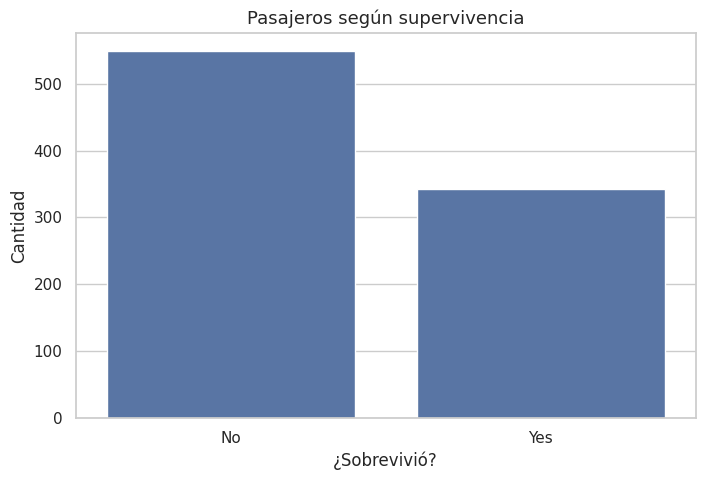

In [ ]:
# 2. Gráfico de conteo de 'Survivor'.

sns.countplot(data=df, x='Survivor')
plt.title('Pasajeros según supervivencia')
plt.xlabel('¿Sobrevivió?')
plt.ylabel('Cantidad')
plt.show()

In [ ]:
# 3. Calcula la tasa general de supervivencia (media de 'Survived').

df['Survived'].mean()

np.float64(0.3838383838383838)

### Paso 17. Supervivencia por clase


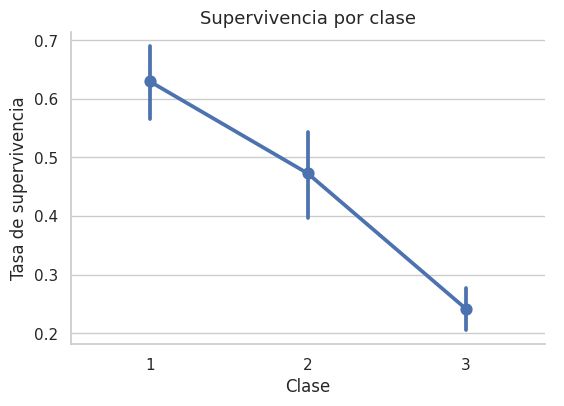

In [ ]:
# Gráfico de puntos: sns.catplot(data=df, x='Pclass', y='Survived', kind='point', height=4, aspect=1.4)
# Añade título con plt.title(...) y etiqueta del eje y: "Tasa de supervivencia".

sns.catplot(data=df, x='Pclass', y='Survived', kind='point', height=4, aspect=1.4)
plt.title('Supervivencia por clase')
plt.xlabel('Clase')
plt.ylabel('Tasa de supervivencia')
plt.show()

### Paso 18. Supervivencia por clase y tipo de persona


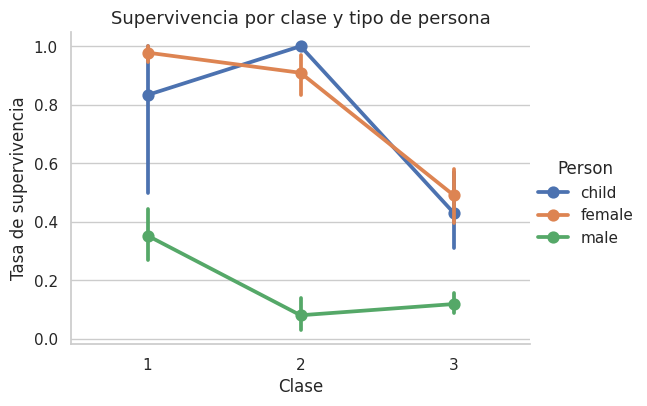

In [ ]:
# Repite el gráfico anterior añadiendo hue='Person' y hue_order=['child', 'female', 'male'].

sns.catplot(data=df, x='Pclass', y='Survived', hue='Person', hue_order=['child', 'female', 'male'], kind='point', height=4, aspect=1.4)
plt.title('Supervivencia por clase y tipo de persona')
plt.xlabel('Clase')
plt.ylabel('Tasa de supervivencia')
plt.show()

### Paso 19. Edad y supervivencia

> **Teoría — `lmplot`.** Dibuja una **recta de regresión** (con banda de confianza) de y contra x. Con `y` binaria (0/1) la recta es solo una *aproximación visual* de la tendencia. El parámetro `x_bins` agrupa la edad en intervalos y dibuja la **tasa media por intervalo**, lo cual es mucho más legible.


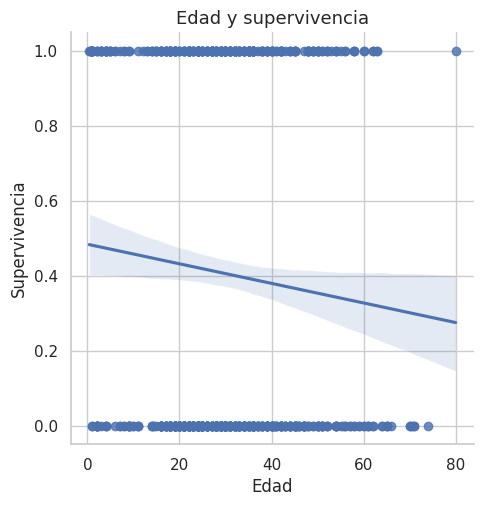

In [ ]:
# 1. sns.lmplot(data=df, x='Age', y='Survived')

sns.lmplot(data=df, x='Age', y='Survived')
plt.title('Edad y supervivencia')
plt.xlabel('Edad')
plt.ylabel('Supervivencia')
plt.show()

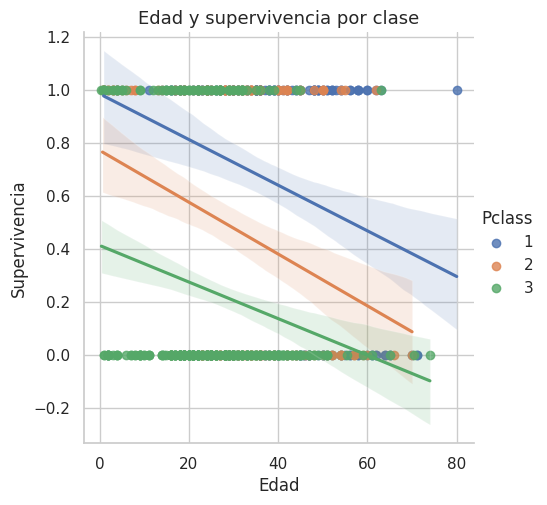

In [ ]:
# 2. Añade hue='Pclass'.

sns.lmplot(data=df, x='Age', y='Survived', hue='Pclass')
plt.title('Edad y supervivencia por clase')
plt.xlabel('Edad')
plt.ylabel('Supervivencia')
plt.show()

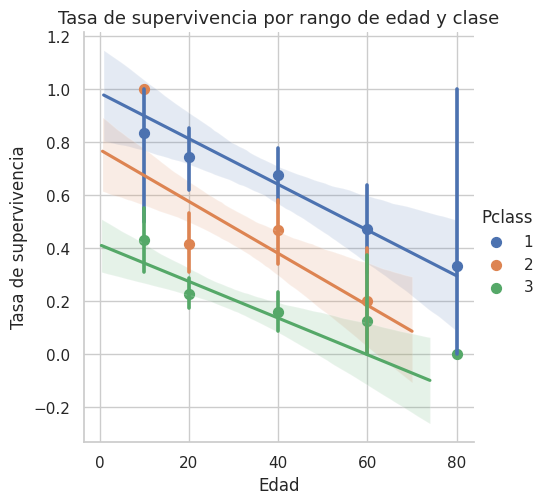

In [ ]:
# 3. Define generaciones = [10, 20, 40, 60, 80] y usa x_bins=generaciones con hue='Pclass'.

generaciones = [10, 20, 40, 60, 80]
sns.lmplot(data=df, x='Age', y='Survived', hue='Pclass', x_bins=generaciones)
plt.title('Tasa de supervivencia por rango de edad y clase')
plt.xlabel('Edad')
plt.ylabel('Tasa de supervivencia')
plt.show()

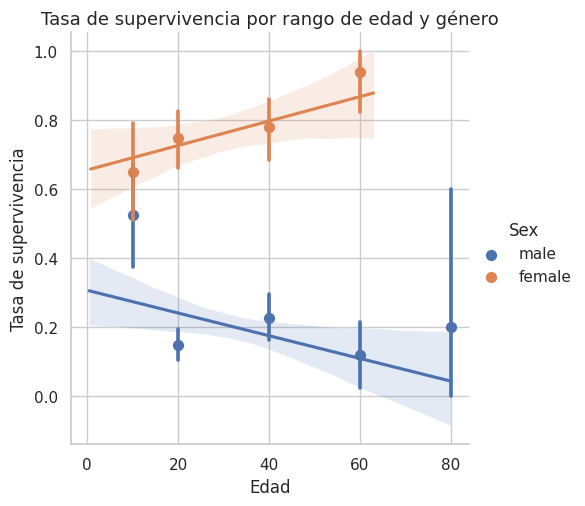

In [ ]:
# 4. Repite el punto 3 con hue='Sex'.

sns.lmplot(data=df, x='Age', y='Survived', hue='Sex', x_bins=generaciones)
plt.title('Tasa de supervivencia por rango de edad y género')
plt.xlabel('Edad')
plt.ylabel('Tasa de supervivencia')
plt.show()

### Paso 20. Relación tarifa-edad


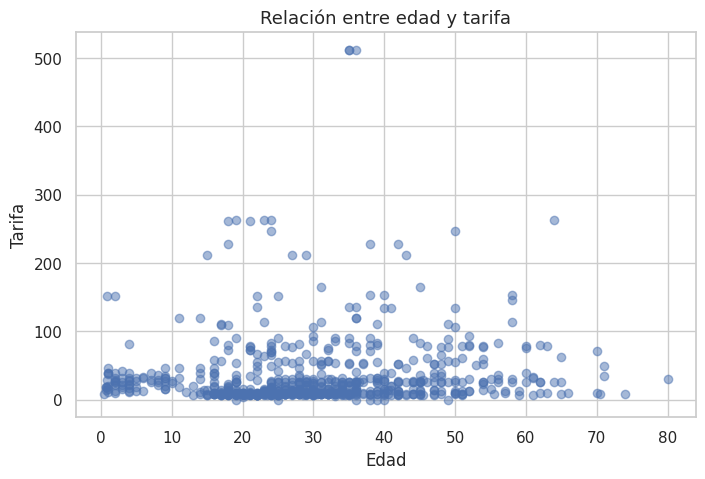

In [ ]:
# 1. Dispersión simple: plt.scatter(df['Age'], df['Fare'], alpha=0.5)

plt.scatter(df['Age'], df['Fare'], alpha=0.5)
plt.title('Relación entre edad y tarifa')
plt.xlabel('Edad')
plt.ylabel('Tarifa')
plt.show()

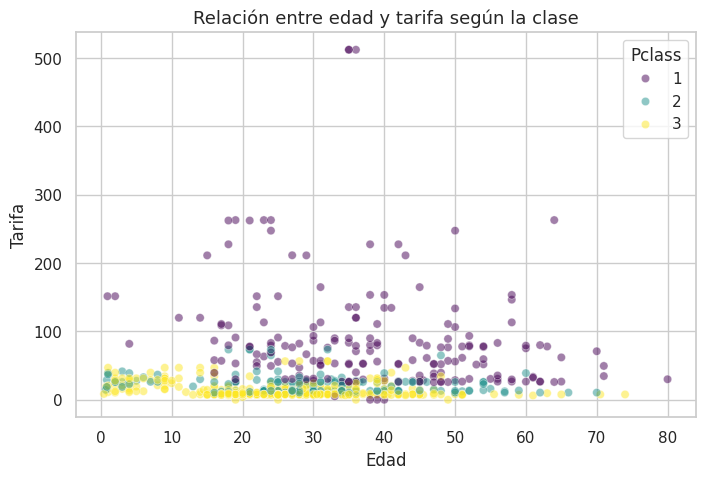

In [ ]:
# 2. Desafío: sns.scatterplot(data=df, x='Age', y='Fare', hue='Pclass', alpha=0.5, palette='viridis')
# Añade título y etiquetas.

sns.scatterplot(data=df, x='Age', y='Fare', hue='Pclass', alpha=0.5, palette='viridis')
plt.title('Relación entre edad y tarifa según la clase')
plt.xlabel('Edad')
plt.ylabel('Tarifa')
plt.show()

### Evaluación — Parte 4


- **E4.1 (conceptual).** ¿Cuál fue la tasa general de supervivencia? ¿Qué clase tuvo mejor tasa y por qué crees que ocurrió?


**Respuesta:** La tasa general de supervivencia fue de 0.384, es decir, cerca del 38.4 % de los pasajeros sobrevivió (Paso 16). Por clase (Paso 17), la primera clase tuvo la mejor tasa (alrededor de 0.63), seguida por la segunda (alrededor de 0.47) y la tercera (alrededor de 0.24). Creo que pudo ocurrir porque los pasajeros de primera clase tenían cabinas y espacios más cercanos a la cubierta de los botes y podían recibir atención o prioridad antes. Con estos datos solo veo la asociación, no puedo comprobar la causa.

- **E4.2 (código).** Construye una **tabla** con la tasa de supervivencia por `Pclass` (filas) y `Person` (columnas). ¿Se cumplió "mujeres y niños primero"? ¿Hay excepciones?


In [ ]:
# Reto E4.2 — Pista: df.pivot_table(values='Survived', index='Pclass', columns='Person', aggfunc='mean')

df.pivot_table(values='Survived', index='Pclass', columns='Person', aggfunc='mean')

Person,child,female,male
Pclass,,,
1,0.833333,0.978022,0.352941
2,1.000000,0.909091,0.080808
3,0.431034,0.491228,0.119122


In [ ]:
# Reto extra: añade aggfunc=['mean', 'count'] para ver también el tamaño de cada grupo.

df.pivot_table(values='Survived', index='Pclass', columns='Person', aggfunc=['mean', 'count'])

mean                     count            
Person     child    female      male child female male
Pclass                                                
1       0.833333  0.978022  0.352941     6     91  119
2       1.000000  0.909091  0.080808    19     66   99
3       0.431034  0.491228  0.119122    58    114  319

- **E4.3 (conceptual).** ¿Era ser hombre en tercera clase particularmente peligroso? ¿Los niños recibieron el mismo trato en todas las clases?


**Respuesta:** Sí fue muy peligroso: según el pivote del E4.2, solo sobrevivió el 11.9 % de los hombres de tercera clase (319 hombres). Aun así, no fue el peor grupo, ya que los hombres de segunda clase tuvieron la tasa más baja (8.1 %); los de primera clase tuvieron 35.3 %. Los niños no recibieron el mismo trato en todas las clases: sobrevivió el 83.3 % de los de primera (solo 6 niños), el 100 % de los de segunda y apenas el 43.1 % de los de tercera.

- **E4.4 (conceptual).** En el Paso 19, ¿existe una tendencia entre edad y supervivencia? ¿Cambia por clase? ¿Y por género? ¿Qué cambia al variar los *bins*?


**Respuesta:** En general (Paso 19) la supervivencia baja a medida que aumenta la edad. Por clase la recta baja en las tres, pero la primera clase se mantiene más arriba a cualquier edad y la tercera más abajo. Por género la tendencia es contraria: en las mujeres la supervivencia sube con la edad y en los hombres baja, así que la tendencia general probablemente se explica en buena parte por los hombres. Al variar los bins cambian los puntos y su intervalo de confianza (los grupos de 60 y 80 años tienen intervalos muy anchos por tener pocos pasajeros), pero la recta casi no cambia porque se ajusta a los datos originales y no a los grupos.

- **E4.5 (conceptual).** En el Paso 18, el intervalo de confianza de los niños de primera clase es muy ancho. ¿Por qué? ¿Qué cuidado implica para interpretar ese punto?


**Respuesta:** El intervalo es muy ancho porque en primera clase solo hay 6 niños (Paso 9 y E4.2). Con tan pocos datos, un solo niño que sobreviva o no cambia mucho la tasa, por lo que la estimación es muy incierta. Hay que tener cuidado de no tomar ese 0.83 como un valor confiable ni compararlo con firmeza con los otros grupos, que tienen muchos más pasajeros.

- **E4.6 (conceptual).** ¿Qué revela el gráfico tarifa-edad coloreado por clase sobre la relación entre tarifa, edad y clase?


**Respuesta:** El gráfico muestra que la tarifa depende mucho más de la clase que de la edad. Las tarifas altas (por encima de 100) son casi todas de primera clase, mientras que los pasajeros de tercera clase se concentran en tarifas bajas. No se ve una relación clara entre la edad y la tarifa: las tarifas más altas aparecen en pasajeros de entre 15 y 65 años aproximadamente, y en todas las edades hay tarifas bajas. Esto indica que la tarifa y la clase aportan información muy parecida.

## Parte 5 — Limpieza y preparación de datos (Pasos 21–26)

> **Teoría — tres decisiones de limpieza.** Un dato faltante puede (a) eliminarse, (b) rellenarse con un valor "razonable" (*imputación*) o (c) conservarse como una categoría propia ("desconocido"). **Ninguna opción es neutral:** cada una cambia lo que los datos dicen. Documenta siempre qué hiciste y por qué.
>
> **Teoría — codificación.** Los modelos y las correlaciones necesitan números. Convertir categorías a números con `.map({...})` crea columnas nuevas (con prefijo `N`). Cuidado: **un número impone un orden** que quizá no existe (¿es "Q = 2" mayor que "S = 0"?).


### Paso 21. Datos faltantes en `Embarked`


In [ ]:
# 1. ¿Cuántos valores faltan en 'Embarked'?

df['Embarked'].isnull().sum()

np.int64(2)

In [ ]:
# 2. Calcula la categoría más frecuente: df['Embarked'].mode()[0]

moda_embarked = df['Embarked'].mode()[0]
moda_embarked

'S'

In [ ]:
# 3. Rellena los faltantes con esa moda usando fillna (asigna el resultado a la columna;
#    evita inplace=True).

df['Embarked'] = df['Embarked'].fillna(moda_embarked)
df['Embarked'].isnull().sum()

np.int64(0)

In [ ]:
# 4. Crea df['NEmbarked'] mapeando S -> 0, C -> 1, Q -> 2.

df['NEmbarked'] = df['Embarked'].map({'S': 0, 'C': 1, 'Q': 2})

### Paso 22. Datos faltantes en `Age`

**Lógica:** en lugar de rellenar con el promedio global, rellenamos con el **promedio de su grupo** (género). Se calcula una tabla `promedio por género` y se "traduce" cada pasajero a su promedio con `.map`.


In [ ]:
# 1. Calcula la edad promedio por género: df.groupby('Sex')['Age'].mean()

promedios = df.groupby('Sex')['Age'].mean()

# Punto 4: se guarda la desviación estándar de Age ANTES de rellenar (para E5.3)
std_antes = df['Age'].std()

promedios

,Age
Sex,
female,27.915709
male,30.726645


In [ ]:
# 2. Rellena los nulos de 'Age': df['Age'] = df['Age'].fillna(df['Sex'].map(promedios))

df['Age'] = df['Age'].fillna(df['Sex'].map(promedios))

In [ ]:
# 3. Verifica que no queden nulos en 'Age'.

df['Age'].isnull().sum()

np.int64(0)

In [ ]:
# 4. Guarda la desviación estándar de 'Age' ANTES de rellenar para compararla en E5.3.

# La desviación estándar se guardó en std_antes antes de rellenar (celda del punto 1)
std_antes

14.526497332334044

### Paso 23. Convertir `Sex` a número


In [ ]:
# Crea df['NSex'] mapeando female -> 0 y male -> 1.

df['NSex'] = df['Sex'].map({'female': 0, 'male': 1})

### Paso 24. Tratamiento de `Cabin`


In [ ]:
# 1. Rellena los nulos de 'Cabin' con 'X' (desconocido).

df['Cabin'] = df['Cabin'].fillna('X')

In [ ]:
# 2. Crea df['TCabin'] con la primera letra de la cabina.

df['TCabin'] = df['Cabin'].str[0]

In [ ]:
# 3. Cuenta los pasajeros por cubierta (value_counts).

df['TCabin'].value_counts()

,count
TCabin,
X,687
C,59
B,47
D,33
E,32
A,15
F,13
G,4
T,1


In [ ]:
# 4. Crea df['NCabin'] asignando un número a cada cubierta:
#    mapa = {letra: i for i, letra in enumerate(sorted(df['TCabin'].unique()))}

mapa = {letra: i for i, letra in enumerate(sorted(df['TCabin'].unique()))}
df['NCabin'] = df['TCabin'].map(mapa)
mapa

{'A': 0, 'B': 1, 'C': 2, 'D': 3, 'E': 4, 'F': 5, 'G': 6, 'T': 7, 'X': 8}

### Paso 25. Extracción de títulos del nombre

> **Teoría — expresiones regulares (regex).** Los nombres tienen la forma `"Braund, Mr. Owen Harris"`. El título está entre la coma y el punto. El patrón `r',\s*([^.]+)\.'` significa: una coma, espacios opcionales (`\s*`), y captura (`( )`) todo lo que no sea un punto (`[^.]+`), hasta el punto. `str.extract(patron, expand=False)` devuelve la parte capturada.


In [ ]:
# 1. Crea df['TTitulo'] = df['Name'].str.extract(r',\s*([^.]+)\.', expand=False).str.strip()

df['TTitulo'] = df['Name'].str.extract(r',\s*([^.]+)\.', expand=False).str.strip()

In [ ]:
# 2. Analiza la frecuencia de cada título (value_counts).

df['TTitulo'].value_counts()

,count
TTitulo,
Mr,517
Miss,182
Mrs,125
Master,40
Dr,7
Rev,6
Col,2
Mlle,2
Major,2


In [ ]:
# 3. Tabla cruzada de título vs. género (pd.crosstab(df['TTitulo'], df['Sex'])).

pd.crosstab(df['TTitulo'], df['Sex'])

Sex,female,male
TTitulo,,
Capt,0,1
Col,0,2
Don,0,1
Dr,1,6
Jonkheer,0,1
Lady,1,0
Major,0,2
Master,0,40
Miss,182,0


### Paso 26. Consolidar títulos

**Lógica:** los títulos raros dejan grupos de 1 o 2 personas: inútiles para estadística. Se agrupan en categorías más generales con `replace` (un diccionario) y `where/isin` (todo lo que no esté en la lista principal pasa a `'Otro'`).



In [ ]:
# 1. Reemplaza con un diccionario:
#      Master -> Mr ;  the Countess, Dona, Mme -> Mrs ;  Lady, Mlle, Ms -> Miss

df['TTitulo'] = df['TTitulo'].replace({'Master': 'Mr', 'the Countess': 'Mrs', 'Dona': 'Mrs', 'Mme': 'Mrs', 'Lady': 'Miss', 'Mlle': 'Miss', 'Ms': 'Miss'})

In [ ]:
# 2. Todo título que NO esté en ['Mr', 'Mrs', 'Miss'] debe pasar a 'Otro'.
#    Pista: df['TTitulo'].where(df['TTitulo'].isin([...]), 'Otro')

df['TTitulo'] = df['TTitulo'].where(df['TTitulo'].isin(['Mr', 'Mrs', 'Miss']), 'Otro')

In [ ]:
# 3. Revisa los conteos finales.

df['TTitulo'].value_counts()

,count
TTitulo,
Mr,557
Miss,186
Mrs,127
Otro,21


In [ ]:
# 4. Crea df['NTitulo'] mapeando Mr -> 0, Mrs -> 1, Miss -> 2, Otro -> 3.

df['NTitulo'] = df['TTitulo'].map({'Mr': 0, 'Mrs': 1, 'Miss': 2, 'Otro': 3})

### Evaluación — Parte 5


- **E5.1 (conceptual).** ¿Es apropiado rellenar `Embarked` con el valor más común? Menciona **dos alternativas** y su costo.


**Respuesta:** Como solo faltan 2 datos de 891 (0.2 %), rellenar con la moda (Southampton, 'S') es razonable y casi no afecta los resultados, pero sigue siendo una suposición, porque no sabemos de verdad dónde embarcaron esas dos personas. Dos alternativas: (1) eliminar esas 2 filas, lo que cuesta perder la información de esos pasajeros (poco aquí, pero sería mucho si faltaran más datos); (2) crear una categoría 'Desconocido', lo que conserva a los pasajeros pero genera una categoría con solo 2 casos, difícil de analizar.

- **E5.2 (código).** Rellenar la edad por género es una opción. Prueba otra: la **mediana por `Pclass` y `Sex`**. Compara los dos resultados para el mismo pasajero. (Pista: necesitas recargar los datos originales para no usar edades ya rellenadas.)


In [ ]:
# Reto E5.2 -> df.groupby(['Pclass', 'Sex'])['Age'].transform('median')

# Se recargan los datos originales en una variable aparte (df_orig) para no tocar df
df_orig = pd.read_csv('https://paste.c-net.org/MarvelJinxed', nrows=891)

# Opción 1: promedio por género (la del Paso 22)
edad_prom_sexo = df_orig['Age'].fillna(df_orig['Sex'].map(df_orig.groupby('Sex')['Age'].mean()))

# Opción 2: mediana por Pclass y Sex
edad_med_grupo = df_orig['Age'].fillna(df_orig.groupby(['Pclass', 'Sex'])['Age'].transform('median'))

# Comparación para los pasajeros que no tenían edad
comparacion = pd.DataFrame({'Pclass': df_orig['Pclass'], 'Sex': df_orig['Sex'], 'Prom. por género': edad_prom_sexo, 'Mediana Pclass+Sex': edad_med_grupo})
comparacion[df_orig['Age'].isnull()].head(10)

,Pclass,Sex,Prom. por género,Mediana Pclass+Sex
5,3,male,30.726645,25.0
17,2,male,30.726645,30.0
19,3,female,27.915709,21.5
26,3,male,30.726645,25.0
28,3,female,27.915709,21.5
29,3,male,30.726645,25.0
31,1,female,27.915709,35.0
32,3,female,27.915709,21.5
36,3,male,30.726645,25.0
42,3,male,30.726645,25.0


- **E5.3 (código + conceptual).** Compara la desviación estándar de `Age` antes y después de rellenar con promedios. ¿Qué pasó con la variabilidad? ¿Qué sesgo introduce el método?


In [ ]:
print('Desviación estándar de Age antes de rellenar:', round(std_antes, 2))
print('Desviación estándar de Age después de rellenar:', round(df['Age'].std(), 2))

Desviación estándar de Age antes de rellenar: 14.53
Desviación estándar de Age después de rellenar: 13.01


**Respuesta:** La desviación estándar de Age bajó de 14.53 a 13.01 después de rellenar con el promedio por género. La variabilidad disminuyó porque a los 177 pasajeros sin edad se les asignó un valor muy cercano al centro (27.9 o 30.7 años), lo que concentra los datos alrededor del promedio. El método introduce un sesgo: subestima la dispersión real de las edades y hace parecer los datos más homogéneos de lo que son. Además, todos los pasajeros sin edad quedan como adultos, incluso si algunos eran niños, y no se tienen en cuenta otras diferencias, como la clase (en E5.2 la mediana por clase y género dio edades distintas).

- **E5.4 (código + ética).** ¿Deberíamos eliminar `Cabin` por tener tantos faltantes? Calcula la tasa de supervivencia de quienes **sí** tienen cabina frente a quienes **no** (`TCabin != 'X'`) y argumenta si "tener cabina registrada" es información en sí misma.


In [ ]:
# Reto E5.4 -> df.groupby(df['TCabin'] != 'X')['Survived'].agg(['mean', 'count'])

df.groupby(df['TCabin'] != 'X')['Survived'].agg(['mean', 'count'])

,mean,count
TCabin,,
False,0.299854,687
True,0.666667,204


**Respuesta:** No necesariamente hay que eliminar Cabin. La tasa de supervivencia de quienes tienen cabina registrada fue de 0.667 (204 pasajeros) frente a 0.300 de quienes no la tienen (687 pasajeros). Es una diferencia grande, así que tener cabina registrada es información en sí misma, y si se elimina la columna se pierde esa señal. Por eso conviene conservarla, por ejemplo con la categoría 'X' (desconocido). Aun así, esto no significa que tener cabina causara sobrevivir: puede que la cabina se registrara más para ciertos pasajeros (por ejemplo, de clases altas o sobrevivientes), así que hay que interpretarlo con cuidado.

- **E5.5 (conceptual).** La consolidación `Master → Mr` junta a niños varones con hombres adultos. ¿Qué información se pierde? ¿Y es discutible que `Lady → Miss`?


**Respuesta:** Al convertir Master en Mr se pierde la información de que eran niños o jóvenes varones: se mezclan 40 niños con los hombres adultos (557 Mr en total), y eso oculta que los niños tuvieron un trato distinto en la evacuación. Cambiar Lady por Miss también es discutible, porque Lady es un título de nobleza y Miss se usaba para mujeres solteras, así que se pierde tanto el estatus social como el estado civil.

- **E5.6 (conceptual — sociológica).** ¿Qué nos revelan los títulos sobre la estructura social de la época?


**Respuesta:** Los títulos muestran una sociedad muy jerarquizada. Los hombres adultos se identificaban como Mr y los niños como Master, pero las mujeres se identificaban por su estado civil (Mrs o Miss). También aparecen títulos de nobleza (Lady, Sir, Don, Jonkheer, the Countess), militares (Col, Major, Capt), religiosos (Rev) y profesionales (Dr), aunque con muy pocos casos. Esto indica que el rango, el estado civil y la profesión eran parte de la identidad de las personas y se reflejaban en el nombre.

- **E5.7 (conceptual).** `NEmbarked`, `NCabin` y `NTitulo` asignan números a categorías **sin orden natural**. ¿Qué riesgo tiene eso al calcular correlaciones o entrenar un modelo? ¿Qué técnica lo evita? (Pista: *one-hot encoding*.)


**Respuesta:** El riesgo es que los números imponen un orden y una distancia que no existen. Por ejemplo, NEmbarked asigna Q = 2 y S = 0, como si Q fuera mayor que S, y en NCabin la cubierta X (desconocida) vale 8 y la A vale 0. Al calcular correlaciones o entrenar un modelo, este tratará esos códigos como valores numéricos con orden, y los resultados pueden cambiar según el orden que se eligió y no tener sentido real. La técnica que lo evita es el one-hot encoding, que crea una columna 0/1 por cada categoría.

## Parte 6 — Correlaciones y estadísticas por grupos (Pasos 27–29)

> **Teoría — correlación de Pearson (repaso del Taller #1).** `df[cols].corr()` produce una **matriz** con la correlación lineal de cada par de variables (−1 a +1). Un **heatmap** con `annot=True` la hace legible. Recuerda: mide relación **lineal**, no implica causalidad, y es poco informativa para variables categóricas codificadas arbitrariamente.



### Paso 27. Matriz de correlación


In [ ]:
# 1. Elige las variables numéricas relevantes:
#    cols = ['Survived', 'Pclass', 'NSex', 'Age', 'SibSp', 'Parch', 'Fare', 'NEmbarked', 'NCabin', 'NTitulo']

cols = ['Survived', 'Pclass', 'NSex', 'Age', 'SibSp', 'Parch', 'Fare', 'NEmbarked', 'NCabin', 'NTitulo']

In [ ]:
# 2. Calcula corr = df[cols].corr()

corr = df[cols].corr()

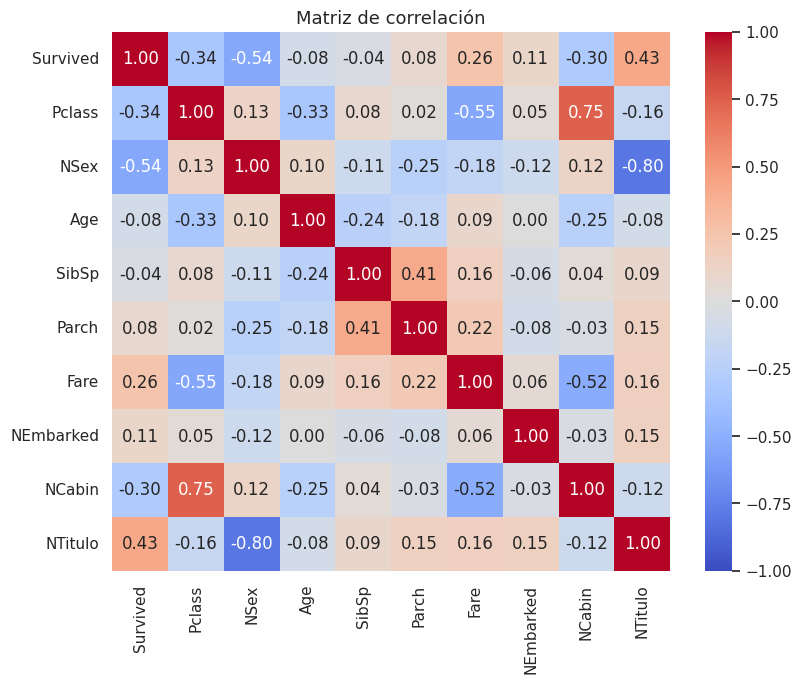

In [ ]:
# 3. Dibuja sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
#    con plt.figure(figsize=(9, 7)).

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Matriz de correlación')
plt.show()

In [ ]:
# 4. Imprime solo la columna de 'Survived' ordenada: corr['Survived'].sort_values()

corr['Survived'].sort_values()

,Survived
NSex,-0.543351
Pclass,-0.338481
NCabin,-0.301116
Age,-0.080453
SibSp,-0.035322
Parch,0.081629
NEmbarked,0.106811
Fare,0.257307
NTitulo,0.428661
Survived,1.000000


### Paso 28. Estadísticas descriptivas por grupos

Genera cuatro tablas con `groupby`:

In [ ]:
# 1. Edad según supervivencia:   df.groupby('Survived')['Age'].describe()

df.groupby('Survived')['Age'].describe()

,count,mean,std,min,25%,50%,75%,max
Survived,,,,,,,,
0,549.0,30.562012,12.460355,1.00,23.0,30.726645,35.0,74.0
1,342.0,28.410122,13.774087,0.42,21.0,27.915709,35.0,80.0


In [ ]:
# 2. Supervivencia por sexo:     df.groupby('Sex')['Survived'].agg(['mean', 'sum', 'count'])

df.groupby('Sex')['Survived'].agg(['mean', 'sum', 'count'])

,mean,sum,count
Sex,,,
female,0.742038,233,314
male,0.188908,109,577


In [ ]:
# 3. Supervivencia por clase:    igual que (2) con 'Pclass'

df.groupby('Pclass')['Survived'].agg(['mean', 'sum', 'count'])

,mean,sum,count
Pclass,,,
1,0.629630,136,216
2,0.472826,87,184
3,0.242363,119,491


In [ ]:
# 4. Supervivencia por 'Alone':  igual que (2) con 'Alone'

df.groupby('Alone')['Survived'].agg(['mean', 'sum', 'count'])

,mean,sum,count
Alone,,,
Alone,0.303538,163,537
with Family,0.505650,179,354


### Paso 29. ¿Es la diferencia por sexo estadísticamente significativa? (Chi-cuadrado)

> **Teoría — prueba de independencia chi-cuadrado.** Compara los conteos observados en una tabla cruzada con los que se esperarían **si las dos variables fueran independientes**.
> - **H₀:** `Sex` y `Survived` son independientes (el sexo no se asocia con sobrevivir).
> - **H₁:** sí hay asociación.
>
> Si `p < 0.05` se rechaza H₀. **Un p-valor pequeño no dice que la asociación sea grande ni causal**, solo que es poco probable que sea azar.


In [ ]:
# 1. Construye la tabla de contingencia: tabla = pd.crosstab(df['Sex'], df['Survived'])

tabla = pd.crosstab(df['Sex'], df['Survived'])

In [ ]:
# 2. Aplica: chi2, p, gl, esperados = stats.chi2_contingency(tabla)

chi2, p, gl, esperados = stats.chi2_contingency(tabla)

In [ ]:
# 3. Imprime chi2 y p, y escribe en un comentario tu conclusión.

print('Chi-cuadrado:', chi2)
print('p-valor:', p)

# Conclusión: p-valor < 0.05, por lo tanto se rechaza H0. Hay una asociación estadísticamente significativa
# entre el sexo y la supervivencia (esto no dice que sea una asociación grande ni que sea causal).

Chi-cuadrado: 260.71702016732104
p-valor: 1.1973570627755645e-58


### Evaluación — Parte 6


- **E6.1 (conceptual).** ¿Qué variables están más correlacionadas con `Survived`? ¿Alguna correlación te sorprende o contradice tus hipótesis iniciales?


**Respuesta:** Según el Paso 27, las variables más correlacionadas con Survived son NSex (-0.54), NTitulo (0.43), Pclass (-0.34), NCabin (-0.30) y Fare (0.26). Las más débiles son Age (-0.08), SibSp (-0.04), Parch (0.08) y NEmbarked (0.11). Me sorprende que la edad casi no se correlacione con sobrevivir (-0.08), porque esperaba que "niños primero" tuviera más peso; puede ser porque la relación no es lineal y porque cambia según el género (Paso 19). Tampoco se ve que viajar con familia ayude (SibSp y Parch cercanas a 0), lo que no apoya mi hipótesis del E3.5, al menos en forma lineal.

- **E6.2 (conceptual).** ¿Qué grupo demográfico tuvo las mejores y las peores tasas de supervivencia, según el Paso 28?


**Respuesta:** Según el Paso 28, los grupos con mejor tasa de supervivencia fueron las mujeres (0.742), la primera clase (0.630) y quienes viajaban con familia (0.506). Los grupos con peor tasa fueron los hombres (0.189), la tercera clase (0.242) y quienes viajaban solos (0.304). En la edad, los sobrevivientes tuvieron un promedio un poco menor (28.4 años) que los no sobrevivientes (30.6 años).

- **E6.3 (código).** Repite el Paso 29 con `Pclass` y `Survived`. ¿Qué concluyes? ¿Por qué esta prueba exige variables categóricas?


In [ ]:
# Reto E6.3

tabla_clase = pd.crosstab(df['Pclass'], df['Survived'])
chi2_c, p_c, gl_c, esperados_c = stats.chi2_contingency(tabla_clase)
print('Chi-cuadrado:', chi2_c)
print('p-valor:', p_c)
print('Grados de libertad:', gl_c)

Chi-cuadrado: 102.88898875696056
p-valor: 4.549251711298793e-23
Grados de libertad: 2


**Respuesta:** El resultado fue chi-cuadrado = 102.89, 2 grados de libertad y p-valor = 4.55e-23. Como p < 0.05 se rechaza H0: la clase y la supervivencia no son independientes, hay una asociación estadísticamente significativa (la tasa baja de 0.63 en primera clase a 0.24 en tercera). Esto no quiere decir que la asociación sea causal. La prueba exige variables categóricas porque trabaja con una tabla de contingencia, es decir, con conteos de cada combinación de categorías, y los compara con los conteos que se esperarían si fueran independientes.

- **E6.4 (conceptual).** `NCabin` se correlaciona con `Survived`. ¿Puedes interpretar el **signo** de esa correlación sin recordar cómo la codificaste? ¿Qué te dice eso sobre el uso de códigos numéricos arbitrarios?


**Respuesta:** No, no se puede interpretar. El signo negativo de NCabin (-0.30) depende de cómo se asignaron los números: se codificó por orden alfabético, por lo que la cubierta X (desconocida) quedó con el código más alto (8), y como esos pasajeros tuvieron menor supervivencia (E5.4), la correlación sale negativa. Si se hubiera codificado en otro orden, el signo y el tamaño cambiarían. Esto muestra que los códigos numéricos arbitrarios no tienen un significado real y que la correlación de Pearson no es adecuada para categorías sin orden.

- **E6.5 (conceptual).** Si `Fare` y `Pclass` están fuertemente correlacionadas (con signo negativo), ¿es un error o es lo esperable? ¿Qué problema generaría usar ambas a la vez en un modelo?


**Respuesta:** No es un error, es lo esperable: la primera clase (Pclass = 1) es la que paga tarifas más altas y la tercera (Pclass = 3) las más bajas, por eso la correlación es negativa (-0.55 en el Paso 27). El signo negativo se debe a que Pclass se codifica con 1 para la clase alta. Usar ambas variables en un modelo genera un problema de multicolinealidad: aportan información muy parecida (redundante), lo que puede hacer inestables los coeficientes y dificulta saber cuál de las dos influye en la supervivencia.

## Parte 7 — Visualizaciones comparativas avanzadas (Pasos 30–31)


### Paso 30. Boxplots múltiples (cuadrícula 2×2)

> **Teoría — boxplot.** La caja va del cuartil 1 al 3 (el 50 % central); la línea interior es la mediana; los "bigotes" llegan hasta 1.5·IQR; los puntos fuera son **candidatos a atípicos**.


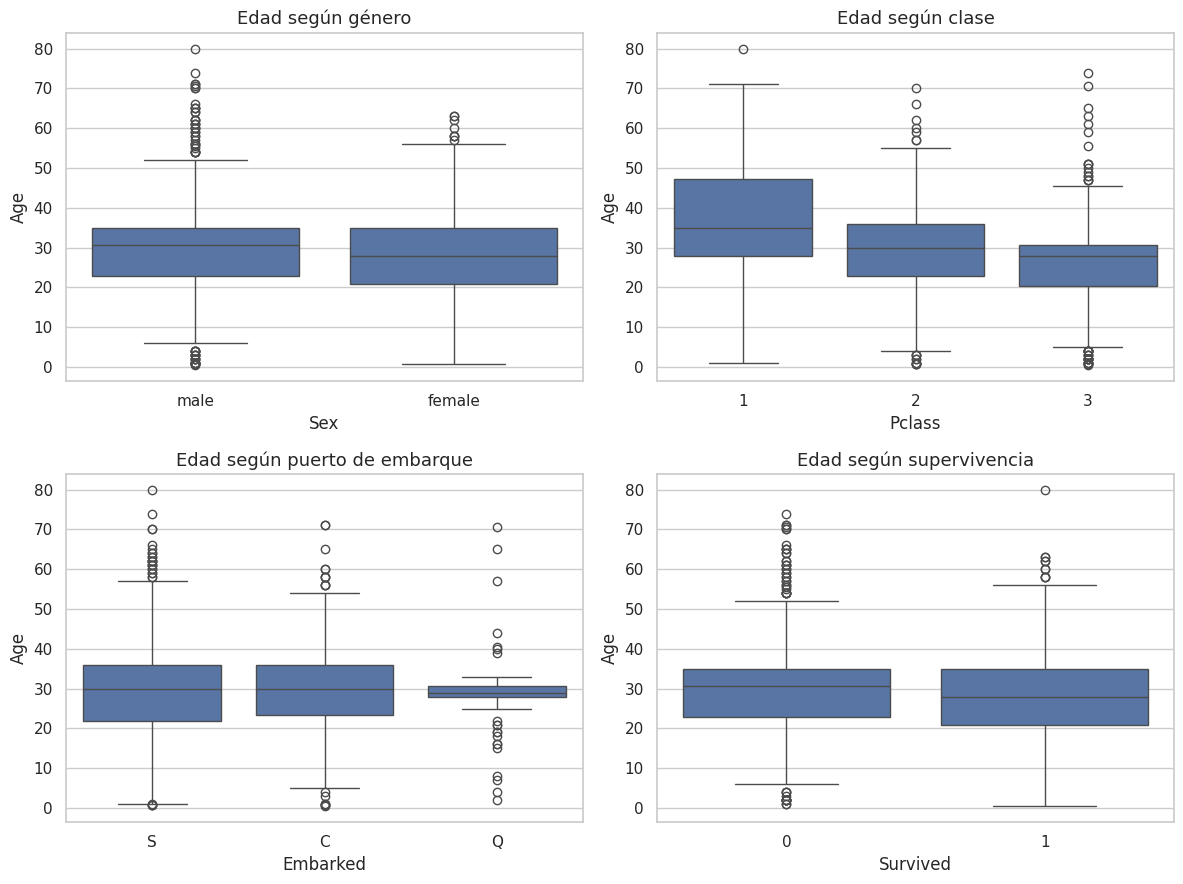

In [ ]:
# 1. fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# 2. Dibuja sns.boxplot(data=df, x=..., y='Age', ax=axes[f, c]) para:
#      axes[0,0] -> x='Sex'     axes[0,1] -> x='Pclass'
#      axes[1,0] -> x='Embarked' axes[1,1] -> x='Survived'

# 3. Cierra con plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

sns.boxplot(data=df, x='Sex', y='Age', ax=axes[0, 0])
axes[0, 0].set_title('Edad según género')

sns.boxplot(data=df, x='Pclass', y='Age', ax=axes[0, 1])
axes[0, 1].set_title('Edad según clase')

sns.boxplot(data=df, x='Embarked', y='Age', ax=axes[1, 0])
axes[1, 0].set_title('Edad según puerto de embarque')

sns.boxplot(data=df, x='Survived', y='Age', ax=axes[1, 1])
axes[1, 1].set_title('Edad según supervivencia')

plt.tight_layout()
plt.show()

### Paso 31. Distribución de la tarifa


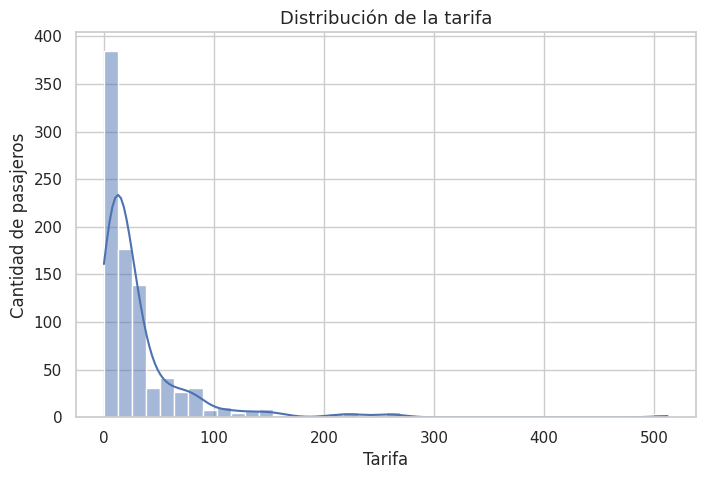

In [ ]:
# 1. Histograma con KDE: sns.histplot(df['Fare'], kde=True, bins=40)

sns.histplot(df['Fare'], kde=True, bins=40)
plt.title('Distribución de la tarifa')
plt.xlabel('Tarifa')
plt.ylabel('Cantidad de pasajeros')
plt.show()

In [ ]:
# 2. Calcula media, mediana y asimetría (skew) de 'Fare'.

print('Media:', df['Fare'].mean())
print('Mediana:', df['Fare'].median())
print('Asimetría (skew):', df['Fare'].skew())

Media: 32.204207968574636
Mediana: 14.4542
Asimetría (skew): 4.787316519674893


### Evaluación — Parte 7


- **E7.1 (conceptual).** ¿Qué revelan los boxplots sobre la edad en distintos grupos? Atención: las edades ya están **imputadas**; ¿cómo afecta eso a lo que ves?


**Respuesta:** Los boxplots muestran que la edad es parecida entre hombres y mujeres (medianas cercanas a 30.7 y 28 años). Por clase hay una diferencia clara: la primera clase tiene la mediana más alta (alrededor de 35 años) y la tercera la más baja (alrededor de 28), con varios atípicos por encima de los 45 años. Por puerto, S y C son similares y Q tiene una caja muy angosta. Los sobrevivientes tienen una mediana un poco menor que los no sobrevivientes. Como las edades están imputadas, esto afecta lo que se ve: a los 177 pasajeros sin edad se les dieron solo dos valores (27.9 y 30.7), por lo que las medianas de hombres y mujeres y de sobrevivientes y no sobrevivientes coinciden con esos valores (Paso 28), y la caja angosta de Q se debe en parte a ese relleno. Las diferencias por género y supervivencia pueden estar influidas por la imputación y no solo por los datos reales.

- **E7.2 (conceptual).** ¿La distribución de `Fare` es normal? ¿Qué te dice sobre la composición socioeconómica del barco? ¿Qué medida de tendencia central es más representativa?


**Respuesta:** No, la distribución de Fare no es normal: es muy asimétrica hacia la derecha (asimetría de 4.79), con muchos pasajeros que pagaron tarifas bajas y una cola larga de tarifas muy altas (hasta 512). La media (32.20) es mucho mayor que la mediana (14.45). Esto indica que a bordo había muchos pasajeros con poco dinero y muy pocos con tarifas muy altas, es decir, una composición socioeconómica desigual. La medida más representativa es la mediana, porque la media se infla por los valores extremos.

- **E7.3 (código).** Dibuja el histograma de `np.log1p(df['Fare'])`. ¿Qué cambió y por qué se usa esta transformación?


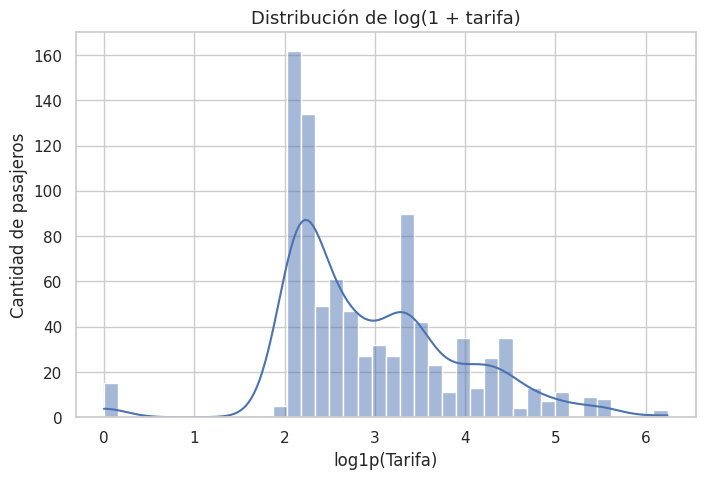

In [ ]:
# Reto E7.3

sns.histplot(np.log1p(df['Fare']), kde=True, bins=40)
plt.title('Distribución de log(1 + tarifa)')
plt.xlabel('log1p(Tarifa)')
plt.ylabel('Cantidad de pasajeros')
plt.show()

**Respuesta:** Con np.log1p la distribución se ve más simétrica: la cola larga de tarifas altas se comprime y los valores extremos pesan menos, aunque todavía quedan varios picos y un grupo en 0 (pasajeros con tarifa 0). Esta transformación se usa para reducir la asimetría y hacer que los datos se parezcan más a una distribución simétrica, lo que ayuda en el análisis y en algunos modelos. Se usa log1p (log de 1 + x) y no log porque hay tarifas de 0 y el logaritmo de 0 no está definido.

## Parte 8 — Preparación del dataset final (Pasos 32–33)


### Paso 32. Limpieza final

**Lógica:** ya creamos versiones numéricas o derivadas de `Name`, `Sex`, `Embarked` y `Cabin`. Las originales se eliminan **en una copia**, de modo que `df` conserve todo para el análisis crítico de la Parte 9.



In [ ]:
# df_final = df.drop(columns=[...]) con las 4 columnas originales a eliminar.

df_final = df.drop(columns=['Name', 'Sex', 'Embarked', 'Cabin'])

### Paso 33. Verificación


In [ ]:
# 1. Confirma que no quedan nulos en las variables clave (isnull().sum()).

df_final.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0
Person,0
Familia,0


In [ ]:
# 2. Revisa los tipos de datos (dtypes) e info().

print(df_final.dtypes)
print()
df_final.info()

PassengerId      int64
Survived         int64
Pclass           int64
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Person          object
Familia          int64
Alone           object
Survivor        object
NEmbarked        int64
NSex             int64
TCabin          object
NCabin           int64
TTitulo         object
NTitulo          int64
dtype: object

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 18 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Age          891 non-null    float64
 4   SibSp        891 non-null    int64  
 5   Parch        891 non-null    int64  
 6   Ticket       891 non-null    object 
 7   Fare         891 non-null    float64
 8   Person       891 non-null    object 
 9  

In [ ]:
# 3. Genera un resumen final con describe().

df_final.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare,Familia,NEmbarked,NSex,NCabin,NTitulo
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.736034,0.523008,0.381594,32.204208,0.904602,0.361392,0.647587,6.716049,0.630752
std,257.353842,0.486592,0.836071,13.014897,1.102743,0.806057,49.693429,1.613459,0.635673,0.477990,2.460739,0.890346
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,22.000000,0.000000,0.000000,7.910400,0.000000,0.000000,0.000000,8.000000,0.000000
50%,446.000000,0.000000,3.000000,30.000000,0.000000,0.000000,14.454200,0.000000,0.000000,1.000000,8.000000,0.000000
75%,668.500000,1.000000,3.000000,35.000000,1.000000,0.000000,31.000000,1.000000,1.000000,1.000000,8.000000,1.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200,10.000000,2.000000,1.000000,8.000000,3.000000


### Evaluación — Parte 8


- **E8.1 (conceptual).** ¿Qué columnas de texto siguen presentes en `df_final`? ¿Podría un modelo de Scikit-Learn usarlas tal cual?


**Respuesta:** En df_final siguen 6 columnas de texto (tipo object): Ticket, Person, Alone, Survivor, TCabin y TTitulo. Un modelo de Scikit-Learn no podría usarlas tal cual, porque trabaja con valores numéricos. Habría que convertirlas a números (como se hace en E8.2 con NAlone y NPerson), usar one-hot encoding o eliminarlas cuando no aportan (por ejemplo, Survivor repite la información de Survived).

- **E8.2 (código).** Convierte `Alone` en una columna numérica `NAlone` (0 = con familia, 1 = solo) y `Person` en `NPerson` (child = 0, female = 1, male = 2).


In [ ]:
# Reto E8.2

df_final['NAlone'] = df_final['Alone'].map({'with Family': 0, 'Alone': 1})
df_final['NPerson'] = df_final['Person'].map({'child': 0, 'female': 1, 'male': 2})

df_final[['Alone', 'NAlone', 'Person', 'NPerson']].head()

,Alone,NAlone,Person,NPerson
0,with Family,0,male,2
1,with Family,0,female,1
2,Alone,1,female,1
3,with Family,0,female,1
4,Alone,1,male,2


- **E8.3 (conceptual).** ¿Tiene sentido conservar `PassengerId` y `Ticket` para predecir supervivencia? Justifica.


**Respuesta:** No tiene mucho sentido. PassengerId es solo un número de identificación secuencial que no tiene relación con haber sobrevivido o no. Ticket es casi único para cada pasajero (681 valores distintos entre 891), así que tal cual no aporta un patrón útil. Si se dejan como variables para predecir, el modelo podría memorizar casos o encontrar patrones que no existen. Sirven para identificar a un pasajero, pero no como variables predictivas.

## Parte 9 — Análisis crítico: interacciones, asociaciones y atípicos (Pasos 34–38)

Esta es la parte donde pasas de **describir** a **argumentar**. Aquí un número solo no basta: hay que preguntarse si es *grande*, si es *confiable* (¿cuántos pasajeros hay detrás?) y si es *justo* compararlo (¿hay una tercera variable que confunde?).

> **Teoría — variable de confusión.** Si el puerto parece influir en la supervivencia, quizá lo que influye es la **clase** (cada puerto trae pasajeros de clases distintas). Para separar efectos se **estratifica**: se compara dentro de cada nivel de la tercera variable.



### Paso 34. Interacciones: clase × género


In [ ]:
# Tabla de tasa de supervivencia con Pclass en filas y Sex en columnas:
# df.pivot_table(values='Survived', index='Pclass', columns='Sex', aggfunc='mean')

df.pivot_table(values='Survived', index='Pclass', columns='Sex', aggfunc='mean')

Sex,female,male
Pclass,,
1,0.968085,0.368852
2,0.921053,0.157407
3,0.500000,0.135447


### Paso 35. Puerto de embarque y supervivencia (¿con confusión?)


In [ ]:
# 1. Tasa de supervivencia y número de pasajeros por 'Embarked' (groupby + agg ['mean', 'count']).

df.groupby('Embarked')['Survived'].agg(['mean', 'count'])

,mean,count
Embarked,,
C,0.553571,168
Q,0.389610,77
S,0.339009,646


In [ ]:
# 2. Repite estratificando por clase: pivot_table con index='Embarked', columns='Pclass'.

df.pivot_table(values='Survived', index='Embarked', columns='Pclass', aggfunc='mean')

Pclass,1,2,3
Embarked,,,
C,0.694118,0.529412,0.378788
Q,0.500000,0.666667,0.375000
S,0.589147,0.463415,0.189802


### Paso 36. Tarifa y supervivencia dentro de cada clase

**Lógica:** para ver si pagar más ayudaba **dentro de una misma clase**, dividimos la tarifa en cuartiles *por clase* con `pd.qcut` y comparamos tasas.


In [ ]:
# 1. Crea df['FareQ'] con cuartiles de Fare calculados dentro de cada Pclass:
#    df['FareQ'] = df.groupby('Pclass')['Fare'].transform(lambda s: pd.qcut(s, 4, labels=False, duplicates='drop'))

df['FareQ'] = df.groupby('Pclass')['Fare'].transform(lambda s: pd.qcut(s, 4, labels=False, duplicates='drop'))

In [ ]:
# 2. pivot_table: tasa de 'Survived' con index='FareQ' y columns='Pclass'.

df.pivot_table(values='Survived', index='FareQ', columns='Pclass', aggfunc='mean')

Pclass,1,2,3
FareQ,,,
0,0.462963,0.345238,0.226562
1,0.574074,0.500000,0.200000
2,0.745455,0.584906,0.275510
3,0.735849,0.589744,0.283333


### Paso 37. Tamaño de la familia


In [ ]:
# 1. Tasa de supervivencia y cantidad de pasajeros por 'Familia' (groupby + agg).

df.groupby('Familia')['Survived'].agg(['mean', 'count'])

,mean,count
Familia,,
0,0.303538,537
1,0.552795,161
2,0.578431,102
3,0.724138,29
4,0.200000,15
5,0.136364,22
6,0.333333,12
7,0.000000,6
10,0.000000,7


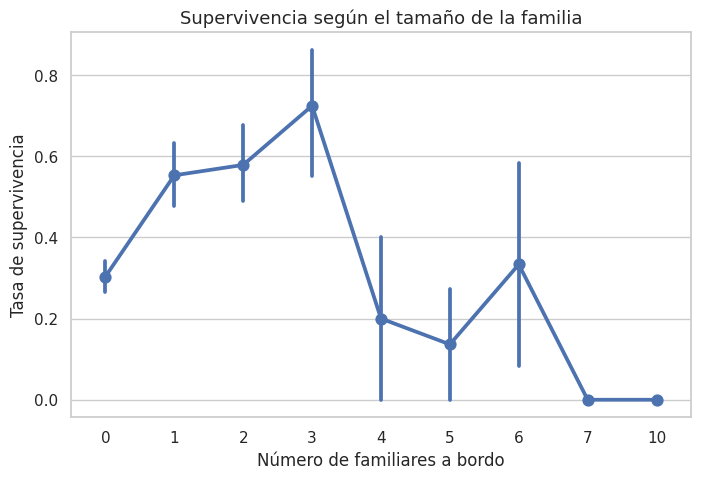

In [ ]:
# 2. Grafica con sns.pointplot(data=df, x='Familia', y='Survived').

sns.pointplot(data=df, x='Familia', y='Survived')
plt.title('Supervivencia según el tamaño de la familia')
plt.xlabel('Número de familiares a bordo')
plt.ylabel('Tasa de supervivencia')
plt.show()

### Paso 38. Pasajeros atípicos

> **Teoría — regla IQR.** `IQR = Q3 − Q1`. Es atípico lo que queda fuera de `[Q1 − 1.5·IQR, Q3 + 1.5·IQR]`. *Atípico no significa erróneo:* antes de eliminar, pregunta si es un error de captura o un caso real.



In [ ]:
# 1. Escribe una función outliers_iqr(serie) que devuelva una máscara booleana
#    (usa serie.quantile([0.25, 0.75])).

def outliers_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)

In [ ]:
# 2. Aplícala a 'Fare', 'Age' y 'Familia' y cuenta cuántos atípicos hay en cada una.

print('Atípicos en Fare:', outliers_iqr(df['Fare']).sum())
print('Atípicos en Age:', outliers_iqr(df['Age']).sum())
print('Atípicos en Familia:', outliers_iqr(df['Familia']).sum())

Atípicos en Fare: 116
Atípicos en Age: 66
Atípicos en Familia: 91


In [ ]:
# 3. Compara la tasa de supervivencia de los atípicos de 'Fare' contra el resto.

df.groupby(outliers_iqr(df['Fare']))['Survived'].agg(['mean', 'count'])

,mean,count
Fare,,
False,0.339355,775
True,0.681034,116


In [ ]:
# 4. Muestra los pasajeros con la tarifa más alta (nlargest).

df.nlargest(10, 'Fare')[['Name', 'Pclass', 'Sex', 'Age', 'Fare', 'Survived']]

,Name,Pclass,Sex,Age,Fare,Survived
258,"Ward, Miss. Anna",1,female,35.0,512.3292,1
679,"Cardeza, Mr. Thomas Drake Martinez",1,male,36.0,512.3292,1
737,"Lesurer, Mr. Gustave J",1,male,35.0,512.3292,1
27,"Fortune, Mr. Charles Alexander",1,male,19.0,263.0000,0
88,"Fortune, Miss. Mabel Helen",1,female,23.0,263.0000,1
341,"Fortune, Miss. Alice Elizabeth",1,female,24.0,263.0000,1
438,"Fortune, Mr. Mark",1,male,64.0,263.0000,0
311,"Ryerson, Miss. Emily Borie",1,female,18.0,262.3750,1
742,"Ryerson, Miss. Susan Parker ""Suzette""",1,female,21.0,262.3750,1
118,"Baxter, Mr. Quigg Edmond",1,male,24.0,247.5208,0


### Evaluación — Parte 9


- **E9.1 (conceptual).** ¿Era ser mujer de tercera clase muy diferente de ser mujer de primera clase? Cuantifica la diferencia con tu tabla del Paso 34.


**Respuesta:** Sí, era muy diferente. Según el Paso 34, sobrevivió el 96.8 % de las mujeres de primera clase frente al 50.0 % de las mujeres de tercera, una diferencia de 46.8 puntos porcentuales (en segunda clase fue 92.1 %). Es decir, ser mujer ayudó mucho, pero la clase marcó una brecha grande: en tercera clase solo sobrevivió la mitad de las mujeres.

- **E9.2 (conceptual).** ¿Los puertos tienen tasas de supervivencia distintas? Tras estratificar por clase, ¿esa diferencia se mantiene? ¿Qué es entonces el puerto: causa o proxy?


**Respuesta:** Sí, las tasas son distintas (Paso 35): Cherbourg 0.554 (168 pasajeros), Queenstown 0.390 (77) y Southampton 0.339 (646). Al estratificar por clase, la ventaja de Cherbourg se reduce pero no desaparece: supera a Southampton en las tres clases (0.694 frente a 0.589 en primera, 0.529 frente a 0.463 en segunda y 0.379 frente a 0.190 en tercera). Queenstown varía más (0.500, 0.667 y 0.375), pero en primera y segunda tiene muy pocos pasajeros (según el Paso 13, solo el 2.6 % y el 3.9 % de sus 77 pasajeros), así que esas tasas no son confiables. Por eso el puerto parece más un proxy de la clase (y quizás de otras variables) que una causa: embarcar en un puerto no hace sobrevivir.

- **E9.3 (conceptual).** ¿Existe una relación no lineal entre tarifa y supervivencia dentro de cada clase? ¿Qué cuidado hay con el tamaño de cada celda?


**Respuesta:** Parece haber una relación no lineal en primera y segunda clase. En primera, la tasa sube de 0.463 en el cuartil más bajo a 0.745 en el tercero y luego se queda casi igual (0.736); en segunda sube de 0.345 a 0.590 y se aplana. En tercera casi no cambia (entre 0.20 y 0.28), así que pagar más dentro de tercera clase casi no ayudó. El cuidado es el tamaño de cada celda: cada cuartil tiene aproximadamente un cuarto de su clase (alrededor de 54 pasajeros en primera, 46 en segunda y 123 en tercera), por lo que las diferencias pequeñas pueden deberse al azar.

- **E9.4 (conceptual).** ¿Hay un número "óptimo" de familiares? ¿Viajar con muchos fue contraproducente? ¿Cuántos pasajeros respaldan los extremos?


**Respuesta:** No hay un número óptimo claro. Según el Paso 37, la tasa es de 0.304 para quienes viajaban solos (537 pasajeros), sube a 0.553 con 1 familiar (161) y 0.578 con 2 (102), y llega a 0.724 con 3 (29). Con 4 o más familiares la tasa baja (0.200, 0.136, 0.333, 0.000 y 0.000), así que viajar con muchos familiares parece haber sido contraproducente. Sin embargo, los extremos están respaldados por muy pocos pasajeros (15, 22, 12, 6 y 7 con 4, 5, 6, 7 y 10 familiares), igual que el máximo de 3 familiares (29), por lo que esos valores no son confiables.

- **E9.5 (código).** Verifica tu hipótesis de E3.5 con una **prueba chi-cuadrado** entre `Alone` y `Survived`. ¿Qué advertencia harías antes de concluir que "viajar con familia ayuda"? (Pista: ¿la gente sola es distinta en edad, sexo o clase?)


In [ ]:
# Retos E9.5

tabla_alone = pd.crosstab(df['Alone'], df['Survived'])
chi2_a, p_a, gl_a, esperados_a = stats.chi2_contingency(tabla_alone)
print('Chi-cuadrado:', chi2_a)
print('p-valor:', p_a)
print('Grados de libertad:', gl_a)

Chi-cuadrado: 36.00051446773864
p-valor: 1.9726543846517183e-09
Grados de libertad: 1


**Respuesta:** La prueba dio chi-cuadrado = 36.00, 1 grado de libertad y p-valor = 1.97e-09. Como p < 0.05 se rechaza H0: hay una asociación significativa entre viajar solo y sobrevivir, y es coherente con mi hipótesis del E3.5 (0.506 con familia frente a 0.304 solo, Paso 28). La advertencia es que esto no prueba que viajar con familia ayude: las personas que viajaban solas pueden ser distintas en edad, sexo o clase (por ejemplo, puede que haya más hombres adultos viajando solos), y esas variables también influyen en la supervivencia, así que la diferencia podría deberse a ellas y no a la familia.

- **E9.6 (conceptual).** ¿Es correcto eliminar automáticamente a los outliers de `Fare`? Da un argumento a favor y uno en contra, citando cómo les fue a esos pasajeros.


**Respuesta:** No es correcto hacerlo de forma automática. A favor: las tarifas muy altas (hasta 512) distorsionan la media (32.20 frente a una mediana de 14.45) y podrían afectar algunos modelos, y representan a muy pocos pasajeros. En contra: no son errores, son casos reales, y además les fue mucho mejor: los 116 pasajeros con tarifa atípica tuvieron una tasa de supervivencia de 0.681 frente a 0.339 del resto (Paso 38), y de las 10 tarifas más altas, todas de primera clase, sobrevivieron 7 (los 3 que no sobrevivieron eran hombres). Eliminarlos haría perder justo la información sobre cómo la riqueza se relaciona con la supervivencia.

## Conclusión y reporte

Responde, **con evidencia de tu análisis** (indica el **Paso** del que proviene cada afirmación) y en un máximo de **8 líneas en total**, sin código:


1. ¿Cuál fue el factor más determinante para la supervivencia?


**Respuesta:** El sexo (correlación -0.54, Paso 27): sobrevivió el 74 % de las mujeres y el 19 % de los hombres (Paso 28).

2. ¿Se confirma "mujeres y niños primero"? ¿Con qué excepciones?


**Respuesta:** Sí: en 1ª y 2ª clase sobrevivió el 98 % y 91 % de las mujeres y el 83 % y 100 % de los niños; excepción: en 3ª solo el 49 % de las mujeres y el 43 % de los niños (E4.2).

3. ¿Cómo influyó la clase social?


**Respuesta:** Mucho: sobrevivió el 63 % en 1ª, 47 % en 2ª y 24 % en 3ª (Paso 28); en mujeres, 97 % (1ª) y 50 % (3ª) (Paso 34).

4. ¿Viajar con familia ayudó o perjudicó?


**Respuesta:** Ayudó con matices: 0.506 con familia frente a 0.304 solo (Paso 28); mejor con 3 familiares (0.724) y peor con 4 o más (Paso 37), posiblemente por confusión con sexo y clase.

5. ¿Qué factores inesperados descubriste?


**Respuesta:** Que la edad casi no se correlaciona con sobrevivir (-0.08, Paso 27) y que los hombres de 2ª clase (8.1 %) sobrevivieron menos que los de 3ª (11.9 %) (E4.2).

Después, en un párrafo corto de **limitaciones**, reflexiona sobre:


- ¿Qué datos faltantes pudieron sesgar tus conclusiones (edad, cabina)?


**Respuesta:** Cabin faltaba en el 77.1 % de los pasajeros y Age en el 19.9 % (E1.3). Es probable que la cabina solo se registrara para ciertos pasajeros (con cabina la supervivencia fue 0.667 frente a 0.300, E5.4), así que las conclusiones por cubierta son parciales. Rellenar la edad con el promedio por género redujo la desviación estándar de 14.53 a 13.01 (E5.3) y dejó como adultos a pasajeros sin edad que podrían haber sido niños (E2.5), lo que puede subestimar el efecto de la edad y de ser niño.

- ¿Qué variables adicionales hubieras querido tener (ubicación en el barco, tiempo de acceso a botes salvavidas, nacionalidad, tripulación)?


**Respuesta:** Me habría gustado tener la ubicación de cada pasajero en el barco (cabina o cubierta para todos), el tiempo que tuvo para llegar a los botes salvavidas, la nacionalidad y si era pasajero o tripulación. Con eso se podría separar el efecto de la clase del efecto de la ubicación y del acceso real a los botes.

- ¿Qué supuestos hiciste que podrían ser cuestionables (promedio por género, `Master → Mr`, códigos numéricos arbitrarios, tratar la muestra como "todo el barco")?


**Respuesta:** Algunos supuestos cuestionables fueron: rellenar la edad con el promedio por género (todos los faltantes reciben el mismo valor), consolidar Master en Mr (mezcla niños con hombres adultos, E5.5), usar códigos numéricos arbitrarios para NEmbarked, NCabin y NTitulo en las correlaciones (E5.7, E6.4) y tratar los 891 pasajeros del archivo como si fueran todo el barco, cuando no incluyen a toda la gente a bordo (por ejemplo, la tripulación).